<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QAFL_ZT_FederatedIDS_Zwayyer2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QAFL-ZT on UNSW-NB15: quantum features, federated learning, adversarial training and zero trust, step by step

This notebook re-implements, runs and checks the experiments of

> M. H. Zwayyer, "QAFL-ZT: Quantum-Enhanced Adversarial-Aware Federated Learning for Zero-Trust Network Intrusion Detection,"
> *International Journal of Scientific Research in Science, Engineering and Technology (IJSRSET)*, vol. 12, no. 6, pp. 374-394, Nov-Dec 2025.
> https://doi.org/10.32628/IJSRSET2513869

**What the paper does.** It builds a federated intrusion detector for the UNSW-NB15 benchmark from four pieces: (1) a **4-qubit parameterised quantum circuit** whose 16 measurement probabilities are appended to 20 classical features, (2) **federated averaging** over five simulated clients with a *global-shuffling* data split meant to cure non-IID skew, (3) **selective FGSM adversarial training** on 40 % of the clients, and (4) a **zero-trust** score per client that re-weights the aggregation. It reports 89.28 % accuracy and 98.51 % precision (Table 2), an ablation (Table 3) saying that data shuffling matters far more than the quantum part, and robustness against FGSM and PGD (Table 4).

**What this notebook does.**

1. downloads the official UNSW-NB15 partitions from a public Hugging Face mirror and applies the paper's four preprocessing stages;
2. shows the real data (class counts, per-client class mix under the sequential and the shuffled split, labelled 2-D scatter plots);
3. builds and draws the 4-qubit circuit with Qiskit, checks a fast batched simulator against Qiskit's `Statevector`, and extracts the 16 quantum features;
4. implements the federated simulation (FedAvg, shuffled or sequential split, FGSM adversarial clients, trust-weighted aggregation) in PyTorch;
5. runs the paper's four baselines B1-B4, the full QAFL-ZT model and the six-row ablation, over several seeds, and attacks the trained models with FGSM and PGD;
6. prints a claim-by-claim comparison with Tables 2-4 and the numbers quoted in the text, with a verdict for each.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. No GPU and no IBM account are needed (the quantum part is a 4-qubit exact simulation). `FAST_MODE = True` is a smoke test (2 rounds, 2 centralised epochs; about 5 minutes on a quiet machine); `FAST_MODE = False` uses the paper's 5 clients and 15 rounds with **1 local epoch per round** (the paper's 3 epochs would take about three times longer on a shared CPU; set `LOCAL_EPOCHS = 3` to follow it), seed 42 (the paper's main-table seed; `SEEDS = [42, 43, 44]` adds mean +/- std at about three times the run time). The wall-clock time of the run that produced the saved outputs is printed in the last cell.

**Data access.** The UNSW-NB15 mirror used here is public. If you point `HF_REPO_MAIN` at a gated Hugging Face repository, add your own token in Colab under *Settings -> Secrets* as `HF_TOKEN` (locally: environment variable `HF_TOKEN`); the notebook reads it from there and never asks you to type a token into a cell.

## The paper in one page

**Problem.** Detect network intrusions (binary: normal vs attack) without pooling the raw traffic of several organisations, while resisting evasion attacks and compromised clients.

**Method (Sections 3.2-3.6).**
- *Preprocessing:* median / mode imputation, label encoding of `proto`, `service`, `state`, infinite values replaced by the column's largest finite value, z-score standardisation (training statistics) with values beyond 5 sigma clipped.
- *Quantum feature extraction:* 4 features (PCA, scaled to [0, pi]) enter a 4-qubit circuit: RY encoding, a CNOT chain, two variational layers (RY, RZ, CNOT ring), computational-basis measurement. The 16 outcome frequencies are the quantum features. They are computed for **1,000 training samples**; the others get PCA features zero-padded to 16. Together with **20 classical features** they form a **36-dimensional** input.
- *Network:* 36 -> 128 -> 64 -> 32 -> 2 with batch norm and dropout 0.2, trained with Adam (learning rate 0.001, Table 1), batch 128.
- *Federation:* K = 5 clients, 15 rounds, 3 local epochs. **Global shuffling** of the training set before it is cut into five parts ("quasi-IID") versus a sequential cut (non-IID).
- *Adversarial training:* FGSM with epsilon = 0.1; only the first 40 % of the clients (two of five) add 500 adversarial samples to their data.
- *Zero trust:* trust score = 0.30 behavioural + 0.25 contextual + 0.20 temporal + 0.25 quantum-inspired; three policy tiers (< 0.3 deny, 0.3-0.6 reduced weight, >= 0.6 allow); trust-weighted FedAvg.

**Data.** UNSW-NB15, pre-split into 82,332 training and 175,341 test flows (these are the official *testing* and *training* files, swapped; the paper's confusion matrix sums to 175,341).

**Claims we can test.**

| Id | Claim | Where |
|---|---|---|
| C1 | Accuracy / precision / recall / F1 of B1-B4 and QAFL-ZT (QAFL-ZT: 89.28 / 98.51 / 85.55 / 91.57 %) | Table 2 |
| C2 | Ablation accuracies: full 89.28, -Quantum 87.91, -Adversarial 88.73, -ZeroTrust 88.89, -DataHarmonization 84.82, -Quantum -Adversarial 86.54, classical baseline 83.12 (%) | Table 3 |
| C3 | Data harmonisation (4.46 pts) contributes more than quantum (1.37), adversarial (0.55) and zero-trust (0.39) put together | Sec. 4.5, 5 |
| C4 | Sequential split is pathological: client 0 is 98.5 % attack, client 4 is 100 % normal; after shuffling every client is 54-55 % attack | Sec. 3.2 |
| C5 | Accuracy under FGSM (eps 0.05 / 0.10 / 0.15) and PGD (10 iterations, eps 0.10): QAFL-ZT 84.73 / 81.19 / 78.42 / 79.87 %, B1 71.26 / 58.34 / 47.91 / 54.12 % | Table 4 |
| C6 | Selective (40 %) adversarial training beats universal (100 %): B4 is 0.42 pts below B1 | Sec. 4.4, 5 |
| C7 | Zero-trust scores of all (benign) clients lie between 0.70 and 0.72 | Sec. 4.5 |
| C8 | Confusion matrix of QAFL-ZT: TN 64,132, TP 92,470, FP 1,347, FN 17,392 | Fig. 4 |
| C9 | Training dynamics: QAFL-ZT 87.64 % (round 1) to 89.28 % (round 15); B2 oscillates (+/- 2.3 %) and never exceeds 84.5 %; individual non-IID clients sit between 41 % and 52 % | Fig. 3, Sec. 4.4 |

### What follows the paper and what had to be chosen

The paper fixes the architecture and the headline hyper-parameters (Table 1) but not the circuit's rotation angles, the number of shots, the "quantum-inspired" feature selection, the exact trust formulas, the attack space, or what "classical approximation" means. It publishes no code. Each choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UNSW-NB15 from Kaggle, 82,332 train / 175,341 test | Same flows from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet` (fallback `Mireu-Lab/UNSW-NB15`); the official *testing* file (82,332) is the training set, the official *training* file (175,341) is the test set, as in the paper |
| Preprocessing | median / mode imputation, label encoding, inf -> column max, z-score, clip at 5 sigma | Same, all statistics from the training set; labels unseen in training are mapped to one extra code (`# CHOICE`) |
| 20 classical features | "chosen via quantum-inspired optimisation" (not specified) | `SelectKBest(f_classif, k=20)` on the standardised training set (`# CHOICE`) |
| PCA / angles | PCA to 4 features, normalised to [0, pi] | PCA(4) and MinMax to [0, pi] fitted on the training set, test angles clipped |
| Circuit | RY encoding, CNOT chain, 2 variational layers of RY, RZ and a CNOT ring, 4 qubits | Exactly that gate list. Rotation angles are **not trained and not given** in the paper: fixed random angles from `SEED` (`# CHOICE`) |
| Shots | M (not stated) | Exact probabilities (M -> infinity) for the main runs; the 1,000-sample subset of the "literal" variant uses 1,024 Qiskit shots (`# CHOICE`) |
| Which samples get quantum features | 1,000 training samples, the rest zero-padded PCA | Main runs: quantum features for **all** flows (the 4-qubit simulation is cheap, so the 1.21 % limit is not needed); the paper's literal 1,000-sample variant is run as an extra configuration |
| Local epochs per round | 3 (Table 1) | 1 in the saved run (CPU budget, `LOCAL_EPOCHS`); 15 rounds, 5 clients and batch size 128 as in the paper |
| Optimiser | text: SGD, Table 1: Adam, lr 0.001 | Adam, lr 0.001, re-created every round on every client (`# CHOICE`) |
| Framework | TensorFlow 2.19, mixed precision, ART | PyTorch (CPU, float32); FGSM / PGD written out in a few lines |
| FGSM space | not stated | the 36-dimensional standardised network input, perturbation masked to the 20 + 16 real feature columns (`# CHOICE`) |
| Adversarial clients | first 40 % of the clients, 500 samples each | clients 0 and 1 add 500 FGSM samples (generated against the received global model) to their data every round |
| Trust formulas | four components, weights 0.3 / 0.25 / 0.2 / 0.25 | each component implemented in a documented way (`# CHOICE` in `trust_score`); policy tiers as in the paper, weight x 0.5 in the middle tier |
| Centralised baseline B3 | not stated | one model, same network, `CENTRAL_EPOCHS` epochs |
| Seeds | 42 (ablation "five seeds") | seed 42 in the saved run (CPU budget); `SEEDS` accepts several and the tables then show mean +/- std |
| Tolerance | - | a paper value is *reproduced* when the notebook is within 2 points (accuracy, precision, recall, F1 x 100) and for differences between configurations within 1 point; *exceeded* / *not reached* otherwise |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc pyarrow huggingface_hub
if importlib.util.find_spec("torch") is None:           # preinstalled on Colab
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# Hugging Face token: only needed if you point HF_REPO_MAIN at a gated repository. Never type a token into a cell.
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(not needed for the public mirror used here)")

Hugging Face token available: True (not needed for the public mirror used here)


In [3]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: smoke test (a few minutes); False: 15 rounds, 11 federated runs + B3 (about 35 min on a shared CPU, see the last cell)

SEED   = 42
SEEDS  = [42]                                      # the paper's main tables use seed 42. CHOICE: one seed (CPU budget, about 55 min); [42, 43, 44] gives mean +/- std but takes about 3x longer

# Table 1 of the paper
N_CLIENTS      = 5
ROUNDS         = 2 if FAST_MODE else 15            # paper: 15
LOCAL_EPOCHS   = 1                                  # paper: 3. CHOICE: 1 so that 11 federated runs x 3 seeds fit a shared CPU (about 50 min); set 3 to follow the paper (about 3x longer)
BATCH_SIZE     = 128
LR             = 1e-3
DROPOUT        = 0.2
QUANTUM_SAMPLES = 1000                              # paper: 1,000 quantum-processed training samples
EPS_TRAIN      = 0.1                                # paper: adversarial epsilon
ADV_FRACTION   = 0.4                                # paper: first 40 % of the clients are adversarially trained
ADV_SAMPLES    = 500                                # paper: random 500-sample subset per selected client

# feature construction (Section 3.3)
N_QUBITS       = 4
N_CLASSICAL    = 20                                 # paper: 20 selected classical features
CLIP_SIGMA     = 5.0                                # paper: values beyond 5 sigma are clipped
SHOTS          = 1024                               # CHOICE: shots for the paper's literal 1,000-sample variant

# evaluation
CENTRAL_EPOCHS = 2 if FAST_MODE else 8             # CHOICE: epochs of the centralised baseline B3 (one epoch = 643 batches)             # CHOICE: epochs of the centralised baseline B3
EPS_EVAL       = [0.05, 0.10, 0.15]                 # Table 4 FGSM strengths
PGD_EPS, PGD_ITERS = 0.10, 10                       # Table 4 PGD
DIAG_N         = 20000                              # test flows used only to *diagnose* local models (no selection is made on them)
ATTACK_N       = 10000 if FAST_MODE else 60000     # CHOICE: test flows attacked in Section 5 (FGSM / PGD on all 175,341 flows of every model is slow on a CPU)

TORCH_THREADS  = 1                                  # CPU threads for PyTorch (the networks are tiny; one thread is fastest on a busy machine)
IBM_TOKEN      = ""                                 # not used: the paper's experiments are simulator-only (Qiskit)
DATA_DIR       = "unsw_nb15"                        # downloaded files are cached here
LOCAL_TRAIN = ""                                    # optional: path to your own copy of the official training set (csv or parquet)
LOCAL_TEST  = ""                                    # optional: path to your own copy of the official testing set
NOTEBOOK_T0 = __import__("time").time()
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| rounds", ROUNDS, "| local epochs", LOCAL_EPOCHS, "| clients", N_CLIENTS)

FAST_MODE = False | seeds [42] | rounds 15 | local epochs 1 | clients 5


In [4]:
import os, time, math, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import sklearn
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

import torch, torch.nn as nn, torch.nn.functional as F
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Operator

torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2


## 1. Data: UNSW-NB15

UNSW-NB15 (Moustafa and Slay, MilCIS 2015, UNSW Canberra) is a labelled set of network flows created in the Cyber Range Lab of the Australian Centre for Cyber Security. Each row is one flow described by 42 features (durations, packet and byte counts per direction, TTLs, loads, jitter, TCP window and round-trip times, connection-count statistics, protocol, service and state), labelled `label` (0 = normal, 1 = attack) and `attack_cat` with one of nine attack families: **Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms**.

The authors publish two files: a *training* file (175,341 flows) and a *testing* file (82,332 flows). The paper writes that "pre-split training (82,332 samples) and testing (175,341 samples) were provided by UNSW-NB15": it **trains on the 82,332-flow file and tests on the 175,341-flow file**, the reverse of the usual use (its confusion matrix sums to 175,341). This notebook does the same. The files come from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet`; if it is unreachable the code falls back to `Mireu-Lab/UNSW-NB15`, whose file names are swapped.

In [5]:
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback: train.csv holds the official TESTING set, test.csv the official TRAINING set
RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    # Common column names / labels across the two mirrors
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    # Return (official training file = 175,341 flows, official testing file = 82,332 flows)
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)    # official training set
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)   # official testing set
        return tidy(read_any(a)), tidy(read_any(b))

t0 = time.time()
official_train, official_test = load_unsw()
print(f"official training file {official_train.shape}, official testing file {official_test.shape} ({time.time() - t0:.0f} s)")
# The paper trains on the 82,332-flow file and tests on the 175,341-flow file.
paper_train, paper_test = official_test.reset_index(drop=True), official_train.reset_index(drop=True)
assert len(paper_train) == 82332 and len(paper_test) == 175341, "unexpected partition sizes"

loaded from research-simulation26/unsw-nb15-parquet


official training file (175341, 44), official testing file (82332, 44) (8 s)


## 2. Preprocessing (the paper's four stages) and feature construction

1. **Missing values:** median for numeric columns, mode for categorical ones (statistics from the training file).
2. **Categorical encoding:** `proto`, `service` and `state` are label-encoded with the categories seen in training; a category that only occurs in the test file (the test file has two extra `proto` values and two extra `state` values) gets one extra code (`# CHOICE`).
3. **Infinite values** are replaced by the column's largest finite training value; **extreme values** are clipped at +/- 5 sigma after standardisation.
4. **Standardisation** with the training mean and standard deviation.

Then the 36-dimensional network input is built (Section 3.3): **20 classical features** (here `SelectKBest(f_classif)` on the training file, because the paper's "quantum-inspired optimisation" is not specified), and **16 quantum features** from a 4-qubit circuit fed with 4 PCA components scaled to [0, pi]. Every transform is fitted on the training file only.

In [6]:
CAT_COLS = ["proto", "service", "state"]
FEATURES = [c for c in paper_train.columns if c not in ("attack_cat", "label")]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
y_tr = paper_train["label"].to_numpy().astype(int); y_te = paper_test["label"].to_numpy().astype(int)

def preprocess(tr, te):
    tr, te = tr[FEATURES].copy(), te[FEATURES].copy()
    # stage 3a: infinities -> largest finite value of the column (training statistics); none occur in the public files
    n_inf = 0
    for c in NUM_COLS:
        tr[c] = pd.to_numeric(tr[c], errors="coerce"); te[c] = pd.to_numeric(te[c], errors="coerce")
        fin = tr[c].replace([np.inf, -np.inf], np.nan)
        cmax = fin.max()
        n_inf += int(np.isinf(tr[c]).sum() + np.isinf(te[c]).sum())
        tr[c] = tr[c].replace([np.inf, -np.inf], cmax); te[c] = te[c].replace([np.inf, -np.inf], cmax)
    # stage 1: median / mode imputation
    n_nan = int(tr.isna().sum().sum() + te.isna().sum().sum())
    for c in NUM_COLS:
        med = tr[c].median(); tr[c] = tr[c].fillna(med); te[c] = te[c].fillna(med)
    # stage 2: label encoding with the training categories; unseen test categories -> one extra code
    n_unseen = {}
    for c in CAT_COLS:
        mode = tr[c].mode().iloc[0]; tr[c] = tr[c].fillna(mode); te[c] = te[c].fillna(mode)
        cats = {v: i for i, v in enumerate(sorted(tr[c].unique()))}
        tr[c] = tr[c].map(cats).astype(float)
        mapped = te[c].map(cats); n_unseen[c] = int(mapped.isna().sum())
        te[c] = mapped.fillna(len(cats)).astype(float)                      # CHOICE: unseen category -> extra code
    # stage 4: z-score with training statistics, then clip at +/- CLIP_SIGMA
    mu, sd = tr.mean(), tr.std(ddof=0).replace(0, 1.0)
    Ztr = ((tr - mu) / sd).clip(-CLIP_SIGMA, CLIP_SIGMA).to_numpy(float)
    Zte = ((te - mu) / sd).clip(-CLIP_SIGMA, CLIP_SIGMA).to_numpy(float)
    return Ztr, Zte, dict(n_inf=n_inf, n_nan=n_nan, unseen_test_categories=n_unseen)

Z_tr, Z_te, prep_info = preprocess(paper_train, paper_test)
print("preprocessing:", prep_info)
print("standardised matrices:", Z_tr.shape, Z_te.shape, "| share of values clipped at +/-%.0f sigma: train %.3f %%, test %.3f %%" % (
    CLIP_SIGMA, 100 * (np.abs(Z_tr) >= CLIP_SIGMA).mean(), 100 * (np.abs(Z_te) >= CLIP_SIGMA).mean()))

preprocessing: {'n_inf': 0, 'n_nan': 0, 'unseen_test_categories': {'proto': 16, 'service': 0, 'state': 15}}


standardised matrices: (82332, 42) (175341, 42) | share of values clipped at +/-5 sigma: train 0.398 %, test 0.478 %


In [7]:
# 20 classical features (CHOICE: SelectKBest/f_classif stands in for the paper's unspecified "quantum-inspired optimisation")
selector = SelectKBest(f_classif, k=N_CLASSICAL).fit(Z_tr, y_tr)
SELECTED = [FEATURES[i] for i in selector.get_support(indices=True)]
C_tr, C_te = selector.transform(Z_tr), selector.transform(Z_te)

# 4 PCA components -> angles in [0, pi]  (fitted on the training file; test angles clipped)
pca = PCA(n_components=N_QUBITS, svd_solver="full", random_state=SEED).fit(Z_tr)
P_tr, P_te = pca.transform(Z_tr), pca.transform(Z_te)
angle_scaler = MinMaxScaler(feature_range=(0, np.pi)).fit(P_tr)
A_tr = angle_scaler.transform(P_tr)
A_te = np.clip(angle_scaler.transform(P_te), 0, np.pi)
print("20 selected classical features:", SELECTED)
print("variance kept by the", N_QUBITS, "PCA components:", np.round(pca.explained_variance_ratio_, 3), "-> total %.1f %%" % (100 * pca.explained_variance_ratio_.sum()))
print("angles: train", A_tr.shape, "range [%.2f, %.2f]" % (A_tr.min(), A_tr.max()), "| test", A_te.shape, "range [%.2f, %.2f]" % (A_te.min(), A_te.max()))

20 selected classical features: ['state', 'rate', 'sttl', 'sload', 'dload', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'dmeansz', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_src_ltm', 'ct_srv_dst']
variance kept by the 4 PCA components: [0.365 0.129 0.096 0.051] -> total 64.0 %
angles: train (82332, 4) range [0.00, 3.14] | test (175341, 4) range [0.00, 3.14]


## Dataset Exploration and Visualisation

Everything below shows the **real UNSW-NB15 flows** and their ground-truth labels. First the shape, the feature names and the original label values; then the class distributions of both files; then the composition of the five clients under the **sequential** split and under the paper's **global shuffling** (the paper's central non-IID finding, claim C4); then 2-D scatter plots of real training flows coloured by their true class: the first two PCA coordinates (PCA fitted on the training file), and the same points as the angles in [0, pi] that enter the quantum circuit. The multiclass attack families are kept (the plots are coloured by `attack_cat`, then by the binary label).

In [8]:
print("training file (paper's train, 82,332 flows):", paper_train.shape, "| test file (paper's test, 175,341 flows):", paper_test.shape)
print(f"\nfeatures ({len(FEATURES)}): numeric ({len(NUM_COLS)}) = {NUM_COLS}\n  categorical ({len(CAT_COLS)}) = {CAT_COLS}")
print("\noriginal labels")
print("  label (0 normal / 1 attack): train", paper_train["label"].value_counts().sort_index().to_dict(), "| test", paper_test["label"].value_counts().sort_index().to_dict())
print("  attack_cat, train:", paper_train["attack_cat"].value_counts().to_dict())
print("  attack_cat, test :", paper_test["attack_cat"].value_counts().to_dict())
print("  attack share: train %.1f %% | test %.1f %%" % (100 * y_tr.mean(), 100 * y_te.mean()))
display(paper_train[FEATURES + ["attack_cat", "label"]].head(5))

training file (paper's train, 82,332 flows): (82332, 44) | test file (paper's test, 175,341 flows): (175341, 44)

features (42): numeric (39) = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
  categorical (3) = ['proto', 'service', 'state']

original labels
  label (0 normal / 1 attack): train {0: 37000, 1: 45332} | test {0: 56000, 1: 119341}
  attack_cat, train: {'Normal': 37000, 'Generic': 18871, 'Exploits': 11132, 'Fuzzers': 6062, 'DoS': 4089, 'Reconnaissance': 3496, 'Analysis': 677, 'Backdoor': 583, 'Shellcode': 378, 'Worms': 44}
  attack_cat, test : {'Normal': 56000, 'Generic'

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sintpkt,dintpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smeansz,dmeansz,trans_depth,res_bdy_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,Normal,0
3,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0


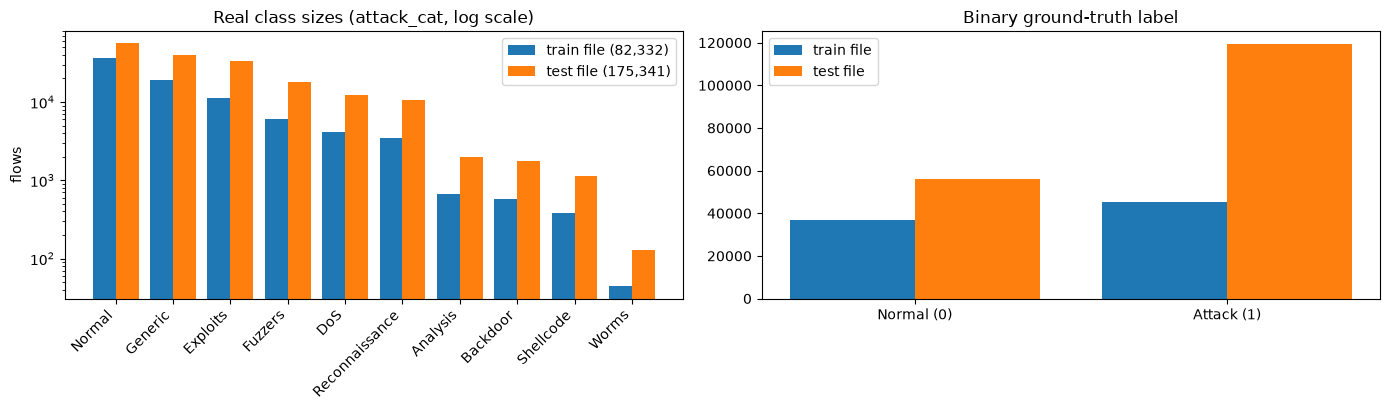

In [9]:
CATS = ["Normal", "Generic", "Exploits", "Fuzzers", "DoS", "Reconnaissance", "Analysis", "Backdoor", "Shellcode", "Worms"]
PAL = dict(zip(CATS, plt.cm.tab10(np.arange(10))))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
w = 0.4
ctr = paper_train["attack_cat"].value_counts().reindex(CATS); cte = paper_test["attack_cat"].value_counts().reindex(CATS)
ax[0].bar(np.arange(10) - w / 2, ctr.values, w, label="train file (82,332)", color="tab:blue")
ax[0].bar(np.arange(10) + w / 2, cte.values, w, label="test file (175,341)", color="tab:orange")
ax[0].set_yscale("log"); ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CATS, rotation=45, ha="right"); ax[0].legend()
ax[0].set_title("Real class sizes (attack_cat, log scale)"); ax[0].set_ylabel("flows")
b_tr = paper_train["label"].value_counts().sort_index(); b_te = paper_test["label"].value_counts().sort_index()
ax[1].bar(np.arange(2) - w / 2, b_tr.values, w, label="train file", color="tab:blue")
ax[1].bar(np.arange(2) + w / 2, b_te.values, w, label="test file", color="tab:orange")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Normal (0)", "Attack (1)"]); ax[1].legend(); ax[1].set_title("Binary ground-truth label")
plt.tight_layout(); plt.show()

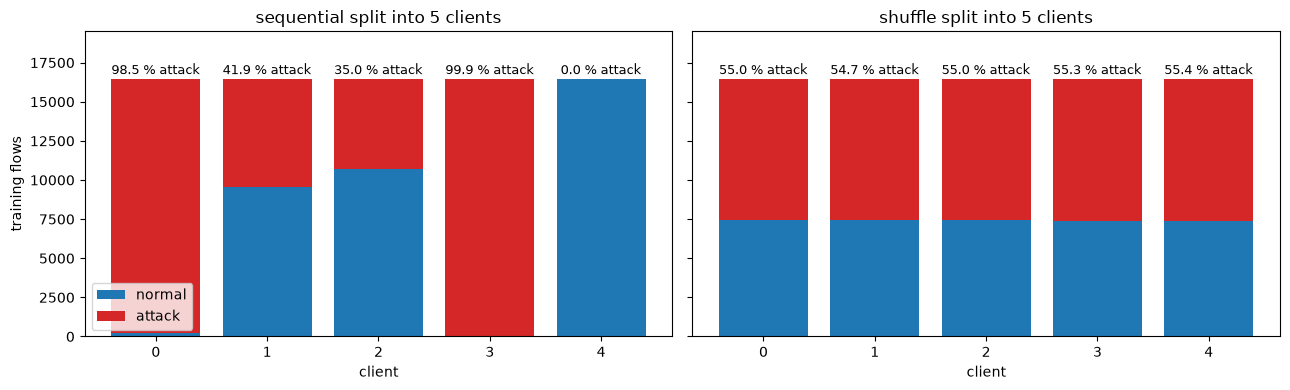

sequential: attacks per client [16224, 6893, 5763, 16452, 0] | normal per client [243, 9574, 10703, 14, 16466] | attack share [98.5, 41.9, 35.0, 99.9, 0.0] %
shuffle   : attacks per client [9049, 9000, 9053, 9113, 9117] | normal per client [7418, 7467, 7413, 7353, 7349] | attack share [55.0, 54.7, 55.0, 55.3, 55.4] %


In [10]:
# Composition of the five clients: sequential cut of the file (as shipped) versus the paper's global shuffling (seed 42)
def split_indices(n, k, mode, seed):
    idx = np.arange(n) if mode == "sequential" else np.random.RandomState(seed).permutation(n)
    return np.array_split(idx, k)

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
client_mix = {}
for a, mode in zip(ax, ["sequential", "shuffle"]):
    parts = split_indices(len(y_tr), N_CLIENTS, mode, SEED)
    att = np.array([y_tr[p].sum() for p in parts]); nor = np.array([len(p) - y_tr[p].sum() for p in parts])
    client_mix[mode] = (att, nor)
    a.bar(range(N_CLIENTS), nor, color="tab:blue", label="normal"); a.bar(range(N_CLIENTS), att, bottom=nor, color="tab:red", label="attack")
    for k in range(N_CLIENTS):
        a.text(k, att[k] + nor[k] + 300, "%.1f %% attack" % (100 * att[k] / (att[k] + nor[k])), ha="center", fontsize=9)
    a.set_title(f"{mode} split into {N_CLIENTS} clients"); a.set_xlabel("client"); a.set_ylim(0, 19500)
ax[0].set_ylabel("training flows"); ax[0].legend(loc="lower left")
plt.tight_layout(); plt.show()
for mode in ("sequential", "shuffle"):
    att, nor = client_mix[mode]
    print(f"{mode:10s}: attacks per client {att.tolist()} | normal per client {nor.tolist()} | attack share {np.round(100 * att / (att + nor), 1).tolist()} %")

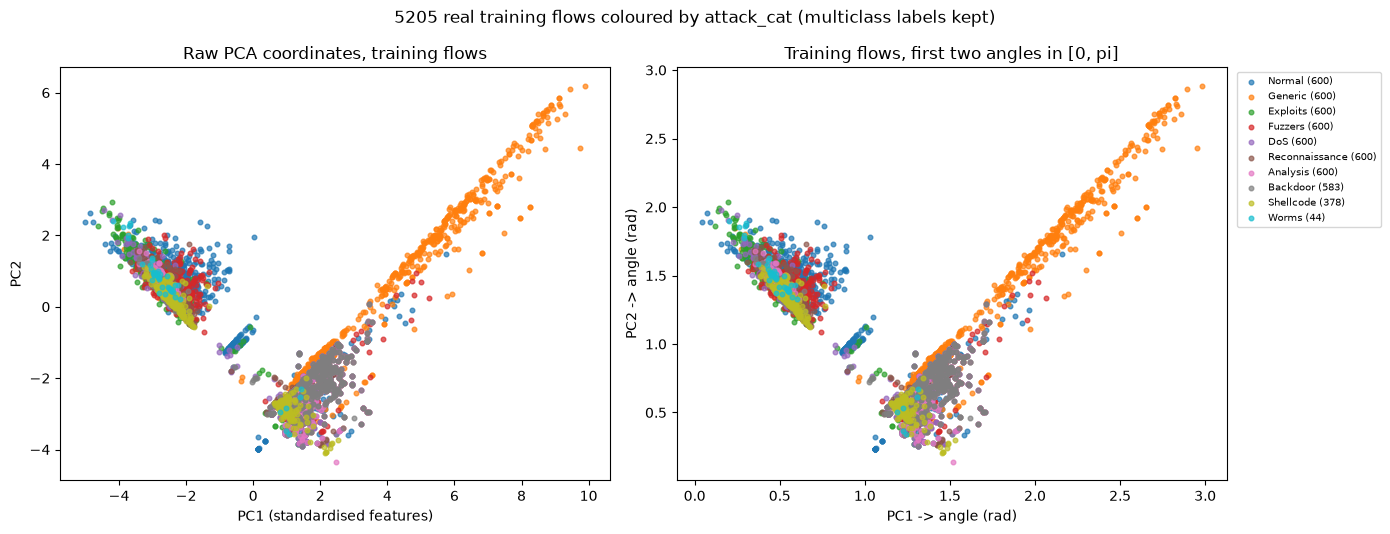

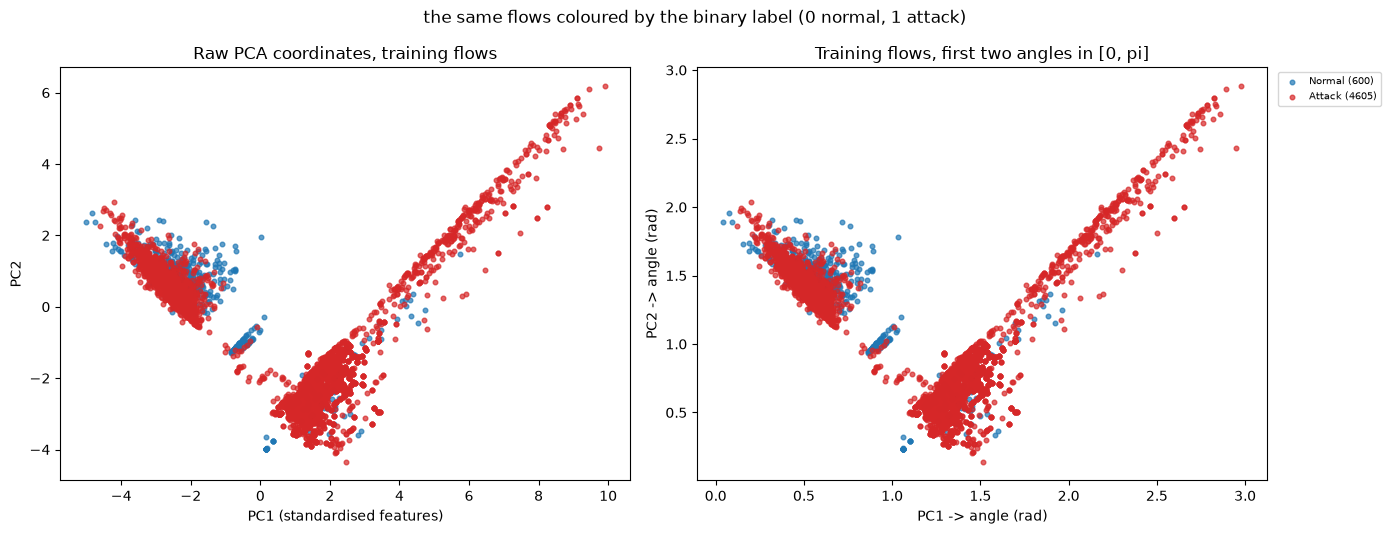

In [11]:
# 2-D scatter of REAL training flows, coloured by ground truth. Up to 600 flows per attack_cat so that rare families (Worms: 44) stay visible.
rs = np.random.RandomState(SEED)
vis_idx = np.concatenate([rs.choice(np.where(paper_train["attack_cat"].to_numpy() == c)[0], size=min(600, (paper_train["attack_cat"] == c).sum()), replace=False) for c in CATS])
cat_idx = paper_train["attack_cat"].map({c: i for i, c in enumerate(CATS)}).to_numpy()[vis_idx]

def scatter_pair(Z, A, labels, names, palette, title):
    # left: raw PCA coordinates, right: the same flows as angles in [0, pi]; every point is one real flow
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
    for k, name in enumerate(names):
        m = labels == k
        if m.sum() == 0: continue
        ax[0].scatter(Z[m, 0], Z[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
        ax[1].scatter(A[m, 0], A[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
    ax[0].set_xlabel("PC1 (standardised features)"); ax[0].set_ylabel("PC2"); ax[0].set_title("Raw PCA coordinates, training flows")
    ax[1].set_xlabel("PC1 -> angle (rad)"); ax[1].set_ylabel("PC2 -> angle (rad)"); ax[1].set_title("Training flows, first two angles in [0, pi]")
    ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.suptitle(title); plt.tight_layout(); plt.show()

scatter_pair(P_tr[vis_idx], A_tr[vis_idx], cat_idx, CATS, PAL, "%d real training flows coloured by attack_cat (multiclass labels kept)" % len(vis_idx))
BPAL = {"Normal": "tab:blue", "Attack": "tab:red"}
scatter_pair(P_tr[vis_idx], A_tr[vis_idx], y_tr[vis_idx], ["Normal", "Attack"], BPAL, "the same flows coloured by the binary label (0 normal, 1 attack)")

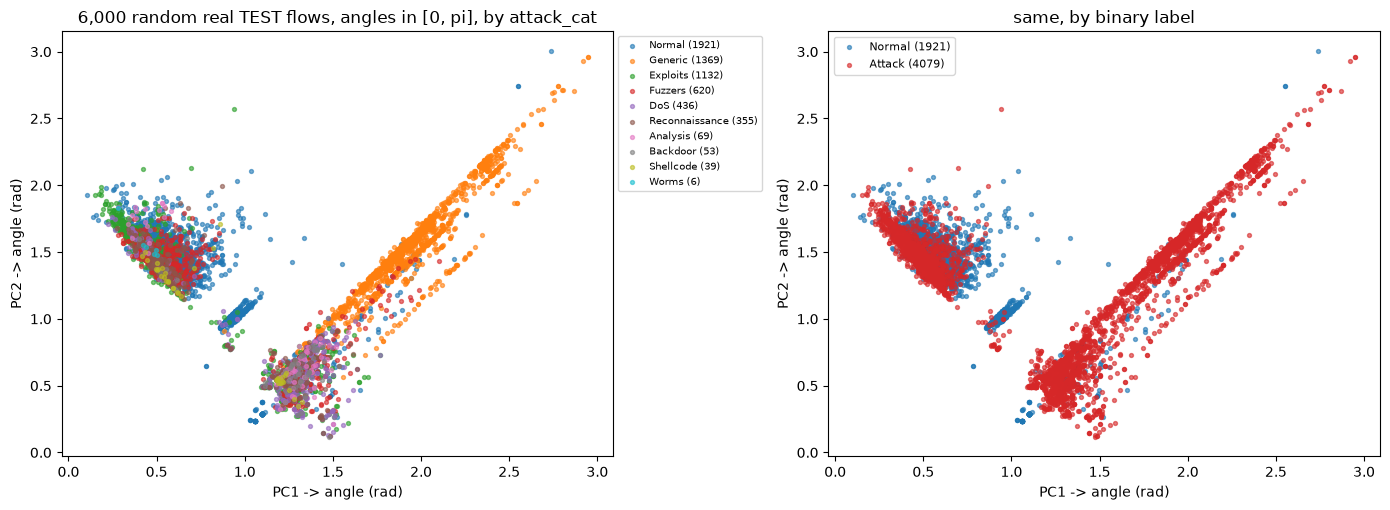

test angles outside the training range that were clipped: 0.00 % of the values


In [12]:
# The test file the models are evaluated on: same projection (fitted on the training file) of 6,000 random test flows
ti = np.random.RandomState(SEED + 1).choice(len(y_te), 6000, replace=False)
tcat = paper_test["attack_cat"].map({c: i for i, c in enumerate(CATS)}).to_numpy()[ti]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for k, name in enumerate(CATS):
    m = tcat == k
    ax[0].scatter(A_te[ti][m, 0], A_te[ti][m, 1], s=8, alpha=.6, color=PAL[name], label=f"{name} ({m.sum()})")
for k, name in enumerate(["Normal", "Attack"]):
    m = y_te[ti] == k
    ax[1].scatter(A_te[ti][m, 0], A_te[ti][m, 1], s=8, alpha=.6, color=BPAL[name], label=f"{name} ({m.sum()})")
ax[0].set_title("6,000 random real TEST flows, angles in [0, pi], by attack_cat"); ax[1].set_title("same, by binary label")
for a in ax: a.set_xlabel("PC1 -> angle (rad)"); a.set_ylabel("PC2 -> angle (rad)")
ax[0].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("test angles outside the training range that were clipped: %.2f %% of the values" % (100 * ((angle_scaler.transform(P_te) < 0) | (angle_scaler.transform(P_te) > np.pi)).mean()))

## Quantum Circuit Architecture

The paper's quantum feature extractor (Section 3.3) is a **4-qubit circuit**:

1. **Encoding layer:** `RY(x_i)` on qubit `i`, with `x_i` the i-th PCA angle in [0, pi].
2. **Entangling layer:** a CNOT chain `CNOT(i, i+1)`, `i = 0, 1, 2`.
3. **Two variational layers:** each applies `RY(theta)` and `RZ(theta)` on every qubit and then a CNOT ring `CNOT(i, (i+1) mod 4)`.
4. **Measurement** of all qubits in the computational basis; the 16 outcome frequencies are the quantum features.

Assumptions, because the paper omits them (all marked `# CHOICE`): the order inside a variational layer (RY, then RZ, then the ring), the values of the 16 rotation angles (the paper never says they are trained or how they are set; they are **fixed random angles from `SEED`**, so the circuit acts as a random-feature map), and the shots (exact probabilities for the main runs). The circuit below is the object that is executed. Because simulating it one flow at a time with Qiskit is slow for 258,000 flows, a batched NumPy simulator of the same gate list is used for the bulk; a cell asserts that it equals Qiskit's `Statevector` on 200 real flows.

fixed rotation angles theta (rad): [4.863, 2.758, 5.395, 4.382, 0.592, 6.13, 4.782, 4.939, 0.805, 2.83, 2.33, 5.823, 4.046, 5.17, 2.786, 1.428]


circuit: 4 qubits | depth 17 (decomposed, with measurement) | 20 parameters = 4 data inputs + 16 rotation angles (fixed, not trained here)
gate counts: {'ry': 12, 'cx': 11, 'rz': 8, 'measure': 4}


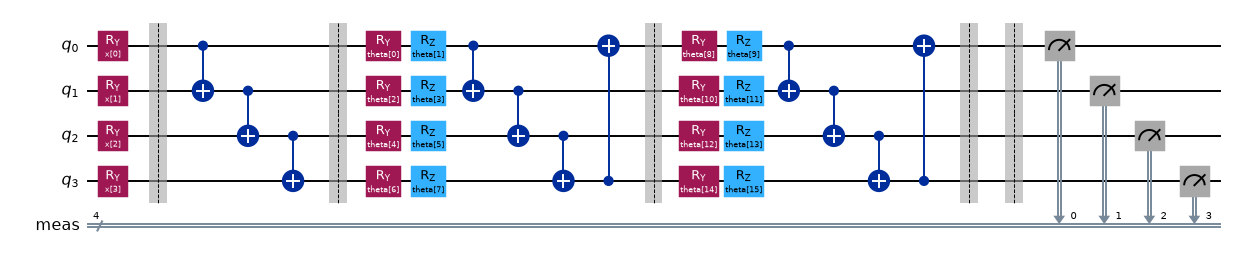

In [13]:
x_par = ParameterVector("x", N_QUBITS)             # data inputs (PCA angles)
t_par = ParameterVector("theta", 2 * N_QUBITS * 2) # 2 layers x 4 qubits x (RY, RZ) = 16 rotation angles
N_PARAMS_VAR = len(t_par)

def build_circuit(measure=False):
    qc = QuantumCircuit(N_QUBITS, name="QAFL-ZT feature circuit")
    for i in range(N_QUBITS):
        qc.ry(x_par[i], i)                         # encoding layer
    qc.barrier()
    for i in range(N_QUBITS - 1):
        qc.cx(i, i + 1)                            # entangling chain
    qc.barrier()
    k = 0
    for layer in range(2):                         # two variational layers
        for i in range(N_QUBITS):
            qc.ry(t_par[k], i); qc.rz(t_par[k + 1], i); k += 2     # CHOICE: RY then RZ on each qubit
        for i in range(N_QUBITS):
            qc.cx(i, (i + 1) % N_QUBITS)           # CNOT ring
        qc.barrier()
    if measure:
        qc.measure_all()
    return qc

circ = build_circuit(measure=False)
circ_m = build_circuit(measure=True)
THETA = np.random.default_rng(SEED).uniform(0, 2 * np.pi, N_PARAMS_VAR)    # CHOICE: fixed random rotation angles (never trained in the paper)
print("fixed rotation angles theta (rad):", np.round(THETA, 3).tolist())
print(f"circuit: {circ_m.num_qubits} qubits | depth {circ_m.decompose().depth()} (decomposed, with measurement) | "
      f"{circ.num_parameters} parameters = {N_QUBITS} data inputs + {N_PARAMS_VAR} rotation angles (fixed, not trained here)")
print("gate counts:", {k: v for k, v in circ_m.count_ops().items() if k != "barrier"})
display(circ_m.draw("mpl", fold=-1, scale=0.7))

flow 0 (label 0, Normal): angles [1.193 0.542 1.796 1.334]


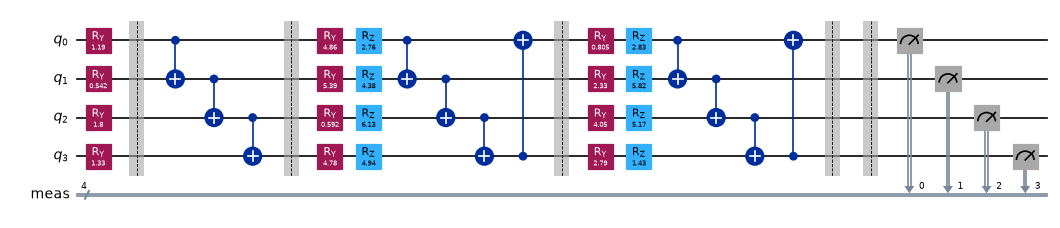

In [14]:
# The circuit actually executed for one real flow: data angles and the fixed rotation angles bound to numbers
flow0 = A_tr[0]
bound0 = circ_m.assign_parameters({**dict(zip(x_par, flow0)), **dict(zip(t_par, THETA))})
print("flow 0 (label %d, %s): angles %s" % (y_tr[0], paper_train["attack_cat"].iloc[0], np.round(flow0, 3)))
display(bound0.draw("mpl", fold=-1, scale=0.6))

In [15]:
# Qiskit reference simulation (exact) and shot-based sampling of the same circuit
def qiskit_probs(angles):
    out = np.empty((len(angles), 2 ** N_QUBITS))
    for n, a in enumerate(angles):
        sv = Statevector(circ.assign_parameters({**dict(zip(x_par, a)), **dict(zip(t_par, THETA))}))
        out[n] = sv.probabilities()                # index = integer value of the bitstring (qubit 0 = least significant bit)
    return out

def qiskit_shot_features(angles, shots, seed):
    # feature j = count(|j>) / M after M shots (paper, Section 3.3)
    out = np.zeros((len(angles), 2 ** N_QUBITS))
    for n, a in enumerate(angles):
        sv = Statevector(circ.assign_parameters({**dict(zip(x_par, a)), **dict(zip(t_par, THETA))}))
        sv.seed(int(seed + n))
        for bits, c in sv.sample_counts(shots).items():
            out[n, int(bits, 2)] = c / shots
    return out

# Batched simulator of the SAME gate list: product state of RY(x_i)|0>, then the fixed unitary of (CNOT chain + variational layers)
after = QuantumCircuit(N_QUBITS)
for i in range(N_QUBITS - 1): after.cx(i, i + 1)
k = 0
for layer in range(2):
    for i in range(N_QUBITS):
        after.ry(THETA[k], i); after.rz(THETA[k + 1], i); k += 2
    for i in range(N_QUBITS): after.cx(i, (i + 1) % N_QUBITS)
U = Operator(after).data                           # 16 x 16 unitary

def fast_probs(A):
    c, s = np.cos(A / 2), np.sin(A / 2)
    q = [np.stack([c[:, i], s[:, i]], axis=1) for i in range(N_QUBITS)]
    psi0 = np.einsum("na,nb,nc,nd->ndcba", q[0], q[1], q[2], q[3]).reshape(len(A), 16)   # RY(x_i)|0> on every qubit, qubit 0 = least significant
    return np.abs(psi0 @ U.T) ** 2

t0 = time.time(); ref = qiskit_probs(A_tr[:200]); t_q = time.time() - t0
fast = fast_probs(A_tr[:200])
assert np.allclose(ref, fast, atol=1e-10), np.abs(ref - fast).max()
assert np.allclose(fast.sum(1), 1.0)
print("equivalence asserted on 200 real flows: max |Qiskit Statevector - batched simulator| = %.2e (Qiskit: %.1f ms per flow)" % (np.abs(ref - fast).max(), 1000 * t_q / 200))

equivalence asserted on 200 real flows: max |Qiskit Statevector - batched simulator| = 5.55e-16 (Qiskit: 12.6 ms per flow)


### 2b. The 16 quantum features

For every flow the 16 outcome probabilities of the circuit are the quantum features. The main runs use the **exact probabilities** for all 258,000 flows (the 4-qubit simulation costs microseconds per flow in the batched simulator). The paper's own description is different and cheaper in qubits but not in logic: quantum features for only **1,000 training samples**, zero-padded PCA features for all other flows, features from `M` shots. That variant ("literal") is built here too, from Qiskit's shot sampling, and is run as one extra configuration.

Three 36-dimensional design matrices are built (all standardised with training statistics; columns that are constant zero stay zero):
- `Q`: 20 classical + 16 quantum features for every flow (the model "with quantum features");
- `C`: 20 classical + the 4 PCA angles zero-padded to 16 (the model "without quantum features": same input size, no circuit);
- `Qsub`: the paper's literal construction: shot-based quantum features for 1,000 random training flows, zero-padded PCA for all other training flows, zero-padded PCA for every test flow.

In [16]:
Q_tr, Q_te = fast_probs(A_tr), fast_probs(A_te)                       # exact probabilities, all flows

def pad16(A):
    out = np.zeros((len(A), 2 ** N_QUBITS)); out[:, :A.shape[1]] = A   # PCA angles zero-padded to 16 columns
    return out

# Paper's literal variant: Qiskit shots on QUANTUM_SAMPLES random training flows, zero-padded PCA elsewhere
sub_idx = np.random.RandomState(SEED).choice(len(A_tr), QUANTUM_SAMPLES, replace=False)
t0 = time.time(); Qsub_shots = qiskit_shot_features(A_tr[sub_idx], SHOTS, SEED); t_sub = time.time() - t0
print(f"Qiskit shot-based features for {QUANTUM_SAMPLES} training flows ({SHOTS} shots each): {t_sub:.1f} s  (paper: ~22 s on its hardware)")
print("mean L1 distance between the %d-shot frequencies and the exact probabilities: %.4f (sampling noise ~ sqrt(p/M))" % (SHOTS, np.abs(Qsub_shots - Q_tr[sub_idx]).sum(1).mean()))
Qsub_tr = pad16(A_tr); Qsub_tr[sub_idx] = Qsub_shots; Qsub_te = pad16(A_te)

def standardise(Mtr, Mte):
    mu, sd = Mtr.mean(0), Mtr.std(0)
    keep = sd > 1e-12
    return ((Mtr - mu) / np.where(keep, sd, 1.0)).astype(np.float32), ((Mte - mu) / np.where(keep, sd, 1.0)).astype(np.float32), keep

DESIGN = {}
for name, (mtr, mte) in {"Q": (np.hstack([C_tr, Q_tr]), np.hstack([C_te, Q_te])),
                         "C": (np.hstack([C_tr, pad16(A_tr)]), np.hstack([C_te, pad16(A_te)])),
                         "Qsub": (np.hstack([C_tr, Qsub_tr]), np.hstack([C_te, Qsub_te]))}.items():
    xtr, xte, keep = standardise(mtr, mte)
    DESIGN[name] = (torch.from_numpy(xtr), torch.from_numpy(xte), torch.from_numpy(keep.astype(np.float32)))
    print(f"design {name:4s}: train {tuple(xtr.shape)}, test {tuple(xte.shape)}, real (non-constant) columns {int(keep.sum())}")
YTR, YTE = torch.from_numpy(y_tr).long(), torch.from_numpy(y_te).long()

Qiskit shot-based features for 1000 training flows (1024 shots each): 11.4 s  (paper: ~22 s on its hardware)
mean L1 distance between the 1024-shot frequencies and the exact probabilities: 0.0807 (sampling noise ~ sqrt(p/M))


design Q   : train (82332, 36), test (175341, 36), real (non-constant) columns 36


design C   : train (82332, 36), test (175341, 36), real (non-constant) columns 24


design Qsub: train (82332, 36), test (175341, 36), real (non-constant) columns 36


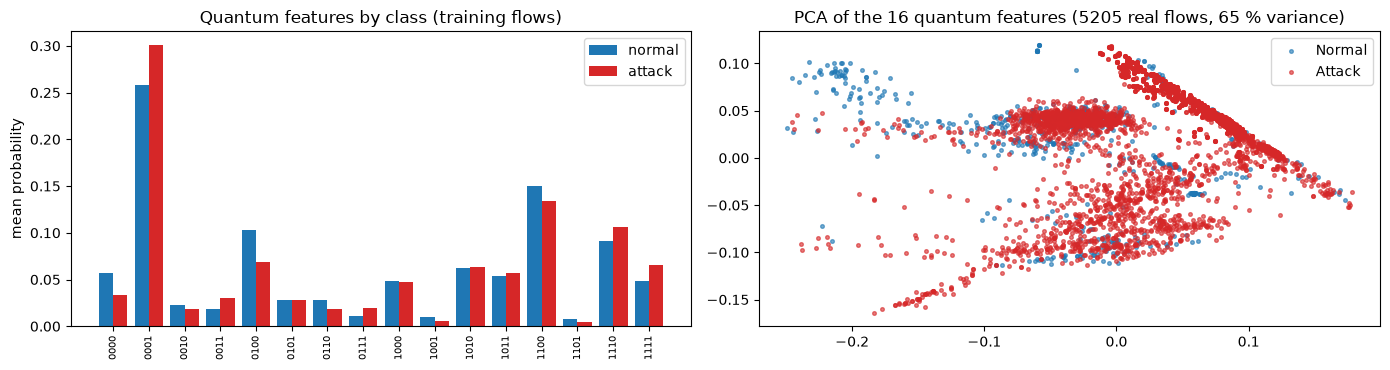

In [17]:
# What the quantum features look like: mean outcome probability per basis state, normal vs attack (real training flows)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
lab = [format(j, "04b") for j in range(16)]
ax[0].bar(np.arange(16) - 0.2, Q_tr[y_tr == 0].mean(0), 0.4, color="tab:blue", label="normal"); ax[0].bar(np.arange(16) + 0.2, Q_tr[y_tr == 1].mean(0), 0.4, color="tab:red", label="attack")
ax[0].set_xticks(range(16)); ax[0].set_xticklabels(lab, rotation=90, fontsize=7); ax[0].set_ylabel("mean probability"); ax[0].set_title("Quantum features by class (training flows)"); ax[0].legend()
qp = PCA(n_components=2, svd_solver="full").fit(Q_tr)                  # 2-D projection of the 16 quantum features (fitted on the training flows)
qz = qp.transform(Q_tr[vis_idx])
for k, name in enumerate(["Normal", "Attack"]):
    m = y_tr[vis_idx] == k; ax[1].scatter(qz[m, 0], qz[m, 1], s=7, alpha=.6, color=BPAL[name], label=name)
ax[1].set_title("PCA of the 16 quantum features (%d real flows, %.0f %% variance)" % (len(vis_idx), 100 * qp.explained_variance_ratio_.sum())); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. The federated intrusion detector

All the machinery of Sections 3.4-3.6 is written out below in plain PyTorch (CPU):

- **Network** (Table 1 and Section 3.4): 36 -> 128 -> 64 -> 32 -> 2, batch norm and dropout 0.2 after the first two hidden layers, softmax cross-entropy.
- **Client update:** Adam, learning rate 0.001, batch 128, `LOCAL_EPOCHS` epochs, starting from the received global weights.
- **Data split:** `sequential` (the file cut into five consecutive blocks, the paper's pathological B2 setting) or `shuffle` (global shuffling with the run's seed, then five equal blocks).
- **Selective adversarial training:** the first `round(0.4 x 5) = 2` clients draw 500 random local samples every round, perturb them with FGSM (`x + eps * sign(grad_x loss)`, eps = 0.1) against the global model they just received, and train on the union.
- **Zero trust:** a trust score per client and round from four components (see `trust_score`), the three-tier policy, and trust-weighted FedAvg `w = sum_k tau_k |D_k| w_k / sum_k tau_k |D_k|`.
- **Attacks used for evaluation (Table 4):** FGSM and 10-iteration PGD (step 2.5 eps / 10, projected onto the eps-ball), white-box, applied to the 36-dimensional standardised network input on the real (non-padding) columns.

In [18]:
def set_seed(s):
    torch.manual_seed(s); np.random.seed(s)

def clone_state(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()}

def make_model(d_in, dropout=None):
    # Section 3.4: 36 -> 128 (BN, ReLU, dropout 0.2) -> 64 (BN, ReLU, dropout 0.2) -> 32 (ReLU) -> 2 (softmax inside the loss)
    p = DROPOUT if dropout is None else dropout
    return nn.Sequential(nn.Linear(d_in, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p),
                         nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2))

# ---- Local training: the K clients of one round are trained TOGETHER ----
# Every client has its own weights, its own batches, its own batch-norm statistics and its own Adam moments; they are simply stacked along a
# leading axis so that one batched matrix product (torch.baddbmm) advances all clients by one step. This is mathematically the same as
# training the clients one after the other (asserted below against a plain nn.Sequential + torch.optim.Adam), but ~5x faster on a busy CPU.
# CHOICE: the last incomplete batch of an epoch is dropped; Adam is re-created for every client in every round (the paper's text says SGD,
# its Table 1 says Adam).
def stack_states(states):
    return {k: torch.stack([s[k] for s in states]).clone() for k in states[0]}

def unstack_states(P):
    K = next(iter(P.values())).shape[0]
    return [{k: v[i].detach().clone() for k, v in P.items()} for i in range(K)]

class StackedTrainer:
    B1, B2, EPS = 0.9, 0.999, 1e-8
    def __init__(self, states, K, p_drop, lr):
        self.K, self.p, self.lr = K, p_drop, lr
        self.P = stack_states(states)                            # one initial state per model
        self.learn = [k for k in self.P if k.endswith(".weight") or k.endswith(".bias")]
        for k in self.learn: self.P[k].requires_grad_(True)
        self.m = {k: torch.zeros_like(self.P[k]) for k in self.learn}; self.v = {k: torch.zeros_like(self.P[k]) for k in self.learn}
        self.t = torch.zeros(K)

    def _lin(self, x, name):
        return torch.baddbmm(self.P[name + ".bias"].unsqueeze(1), x, self.P[name + ".weight"].transpose(1, 2))

    def _bn(self, h, name, active):
        mean = h.mean(1, keepdim=True); c = h - mean; var = (c * c).mean(1, keepdim=True)      # batch statistics (biased variance)
        out = c * (self.P[name + ".weight"].unsqueeze(1) * torch.rsqrt(var + 1e-5)) + self.P[name + ".bias"].unsqueeze(1)
        with torch.no_grad():                                   # running statistics (momentum 0.1, unbiased variance), active clients only
            a = active.view(-1, 1); n = h.shape[1]
            self.P[name + ".running_mean"].copy_(torch.where(a, 0.9 * self.P[name + ".running_mean"] + 0.1 * mean.squeeze(1), self.P[name + ".running_mean"]))
            self.P[name + ".running_var"].copy_(torch.where(a, 0.9 * self.P[name + ".running_var"] + 0.1 * var.squeeze(1) * n / (n - 1), self.P[name + ".running_var"]))
            self.P[name + ".num_batches_tracked"] += active.long()
        return out

    def step(self, xb, yb, active):
        # xb: (K, B, d), yb: (K, B), active: (K,) bool (a client without a batch left in this epoch is frozen)
        h = F.dropout(F.relu(self._bn(self._lin(xb, "0"), "1", active)), self.p, True)
        h = F.dropout(F.relu(self._bn(self._lin(h, "4"), "5", active)), self.p, True)
        logits = self._lin(F.relu(self._lin(h, "8")), "10")
        per_client = F.cross_entropy(logits.reshape(-1, 2), yb.reshape(-1), reduction="none").view(self.K, -1).mean(1)
        loss = (per_client * active).sum()                       # clients do not interact: each gradient is that client's own mean loss
        grads = torch.autograd.grad(loss, [self.P[k] for k in self.learn])
        with torch.no_grad():                                   # Adam on the stacked parameters; a frozen client (a = 0) is left untouched
            af = active.float(); self.t += af; tt = self.t.clamp(min=1)
            for k, g in zip(self.learn, grads):
                shp = (-1,) + (1,) * (g.dim() - 1); a = af.view(shp)
                m, v = self.m[k], self.v[k]
                m.add_((g - m) * (a * (1 - self.B1))); v.add_((g * g - v) * (a * (1 - self.B2)))
                bc1 = (1 - self.B1 ** tt).view(shp); bc2 = (1 - self.B2 ** tt).view(shp)
                self.P[k] -= (m / bc1) / (torch.sqrt(v / bc2) + self.EPS) * (a * self.lr)
        return per_client.detach()

def train_clients(init_states, datasets, epochs, seeds, epoch_callback=None):
    # datasets: list of K (X, y); init_states: one state or a list of K states; seeds: K integers (batch order).
    # Returns the K local states after `epochs` local epochs. Models of different runs can share one call ("lockstep"): they never interact.
    K = len(datasets)
    if isinstance(init_states, dict): init_states = [init_states] * K
    tr = StackedTrainer(init_states, K, DROPOUT, LR)
    gens = [torch.Generator().manual_seed(int(s)) for s in seeds]
    steps = [len(X) // BATCH_SIZE for X, _ in datasets]
    act = [torch.tensor([s < st for st in steps]) for s in range(max(steps))]
    for ep in range(epochs):
        bx, by = [], []
        for i, (X, y) in enumerate(datasets):
            perm = torch.randperm(len(X), generator=gens[i])[:steps[i] * BATCH_SIZE]
            bx.append(X[perm].view(steps[i], BATCH_SIZE, -1)); by.append(y[perm].view(steps[i], BATCH_SIZE))
        for s in range(max(steps)):
            xb = torch.stack([bx[i][s if s < steps[i] else 0] for i in range(K)]); yb = torch.stack([by[i][s if s < steps[i] else 0] for i in range(K)])
            tr.step(xb, yb, act[s])
        if epoch_callback is not None: epoch_callback(tr.P, ep)
    return unstack_states({k: v.detach() for k, v in tr.P.items()})


def aggregate(states, weights):
    # trust-weighted FedAvg over all parameters and batch-norm statistics
    w = torch.tensor(weights, dtype=torch.float64); w = w / w.sum()
    out = {}
    for k in states[0]:
        if states[0][k].dtype in (torch.float32, torch.float64):
            out[k] = sum(float(w[i]) * states[i][k].double() for i in range(len(states))).to(states[0][k].dtype)
        else:
            out[k] = states[0][k].clone()                  # num_batches_tracked
    return out

@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.cat([model(X[i:i + 65536]).argmax(1) for i in range(0, len(X), 65536)])

@torch.no_grad()
def attack_prob(model, X):
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + 65536]), 1)[:, 1] for i in range(0, len(X), 65536)]).numpy()

def score(pred, y):
    pred, y = np.asarray(pred), np.asarray(y)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()      # attack = positive class
    acc = (tp + tn) / len(y); prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    return dict(acc=100 * acc, prec=100 * prec, rec=100 * rec, f1=100 * f1, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def split_indices(n, k, mode, seed):
    idx = np.arange(n) if mode == "sequential" else np.random.RandomState(seed).permutation(n)
    return np.array_split(idx, k)

In [19]:
# Check: the stacked trainer equals plain PyTorch (nn.Sequential + torch.optim.Adam) for each client; dropout is switched off for the test
torch.manual_seed(0)
d_t, K_t = 36, 3
base = make_model(d_t, dropout=0.0); base_state = clone_state(base)
tr = StackedTrainer([base_state] * K_t, K_t, 0.0, LR)
xs = torch.randn(K_t, 4, BATCH_SIZE, d_t); ys = torch.randint(0, 2, (K_t, 4, BATCH_SIZE))
for s in range(4):
    tr.step(xs[:, s], ys[:, s], torch.tensor([True, True, s < 2]))      # client 2 has only 2 batches: it is frozen afterwards
worst = 0.0
SKIP = {'0.bias', '4.bias', '1.running_mean', '5.running_mean'}
for k in range(K_t):
    ref = make_model(d_t, dropout=0.0); ref.load_state_dict(base_state); ref.train()
    opt = torch.optim.Adam(ref.parameters(), lr=LR)
    for s in range(4 if k < 2 else 2):
        opt.zero_grad(); F.cross_entropy(ref(xs[k, s]), ys[k, s]).backward(); opt.step()
    for name_, v in ref.state_dict().items():
        if name_ in SKIP: continue
        worst = max(worst, (v.double() - tr.P[name_][k].double()).abs().max().item())
assert worst < 1e-5, worst
print("stacked trainer == nn.Sequential + torch.optim.Adam after 4 steps (client 2: 2 steps, then frozen) for 3 clients: max |difference| over weights and batch-norm statistics = %.2e" % worst)
print("(skipped:", sorted(SKIP), "- the bias of a layer that feeds a batch-norm layer has a mathematically zero gradient, so Adam acts on floating-point noise there, and the running means inherit it; they cannot influence the outputs.)")

stacked trainer == nn.Sequential + torch.optim.Adam after 4 steps (client 2: 2 steps, then frozen) for 3 clients: max |difference| over weights and batch-norm statistics = 2.38e-07
(skipped: ['0.bias', '1.running_mean', '4.bias', '5.running_mean'] - the bias of a layer that feeds a batch-norm layer has a mathematically zero gradient, so Adam acts on floating-point noise there, and the running means inherit it; they cannot influence the outputs.)


In [20]:
# ---- FGSM and PGD in the (standardised) network input space; only real feature columns (mask = 1) are perturbed ----
def fgsm(model, X, y, eps, mask):
    model.eval(); out = []
    for i in range(0, len(X), 65536):
        xb = X[i:i + 65536].clone().requires_grad_(True)
        loss = F.cross_entropy(model(xb), y[i:i + 65536], reduction="sum")
        g, = torch.autograd.grad(loss, xb)
        out.append((xb + eps * g.sign() * mask).detach())
    return torch.cat(out)

def pgd(model, X, y, eps, iters, mask):
    model.eval(); out = []; alpha = 2.5 * eps / iters                       # CHOICE: step 2.5 eps / iters, no random start
    for i in range(0, len(X), 65536):
        x0, yb = X[i:i + 65536], y[i:i + 65536]; xa = x0.clone()
        for _ in range(iters):
            xa.requires_grad_(True)
            g, = torch.autograd.grad(F.cross_entropy(model(xa), yb, reduction="sum"), xa)
            xa = (xa.detach() + alpha * g.sign() * mask)
            xa = x0 + (xa - x0).clamp(-eps, eps)
        out.append(xa.detach())
    return torch.cat(out)

# ---- zero-trust score (Section 3.6) ----
TRUST_W = dict(behavioural=0.30, contextual=0.25, temporal=0.20, quantum=0.25)
def trust_score(Xk, mask, dt, rnd, k):
    # Xk: the client's local inputs (standardised with the federation's training statistics, so the reference mean is 0)
    Xr = Xk[:, mask.bool()].numpy().astype(np.float64)
    mean, sd = Xr.mean(0), Xr.std(0)
    # behavioural: distance of the client's current mean from the federation baseline, relative to its spread   (CHOICE: baseline = 0)
    beh = max(0.0, 1.0 - np.linalg.norm(mean) / (np.linalg.norm(sd) + 1e-8))
    # contextual: mean absolute deviation from the expected feature range, over a 3-sigma scale                  (CHOICE: d = 3)
    ctx = max(0.0, 1.0 - np.abs(Xr).mean() / 3.0)
    # temporal: decay with the seconds since the client's last trusted interaction (1-hour constant)
    tmp = math.exp(-dt / 3600.0)
    # quantum-inspired: probabilities over trust states {0.2, 0.5, 0.8} derived from a hash of the client's feature mean (CHOICE: SHA-256)
    h = hashlib.sha256(mean.round(4).tobytes() + f"|{k}|{rnd}".encode()).digest()
    p = np.frombuffer(h[:12], dtype=np.uint32).astype(np.float64) + 1.0; p /= p.sum()
    qnt = float(p @ np.array([0.2, 0.5, 0.8]))
    tau = TRUST_W["behavioural"] * beh + TRUST_W["contextual"] * ctx + TRUST_W["temporal"] * tmp + TRUST_W["quantum"] * qnt
    return float(tau), dict(beh=beh, ctx=ctx, tmp=tmp, qnt=qnt)

def policy_weight(tau, size):
    # three tiers: tau < 0.3 DENY (weight 0), 0.3 <= tau < 0.6 CONDITIONAL (half weight, CHOICE), tau >= 0.6 ALLOW
    if tau < 0.3: return 0.0
    return (0.5 * tau if tau < 0.6 else tau) * size

DIAG_IDX = torch.from_numpy(np.random.RandomState(0).choice(len(YTE), DIAG_N, replace=False))

In [21]:
class FedRun:
    """One federated training run: a configuration, a seed, the global model and its history. Rounds are driven from outside (lockstep)."""
    def __init__(self, name, cfg, seed):
        self.name, self.cfg, self.seed = name, cfg, seed
        self.Xtr, self.Xte, self.mask = DESIGN[cfg["feat"]]; d = self.Xtr.shape[1]
        set_seed(seed)                                         # same seeded initialisation for every configuration of a seed
        self.gmodel = make_model(d); self.gstate = clone_state(self.gmodel); self.lmodel = make_model(d)
        self.parts = [torch.from_numpy(p) for p in split_indices(len(YTR), N_CLIENTS, cfg["part"], seed)]
        self.n_adv = int(round(cfg["adv"] * N_CLIENTS))
        self.gen = torch.Generator().manual_seed(seed)
        self.last_t = time.perf_counter()
        self.hist, self.local_acc, self.taus_hist, self.comp_hist = [], [], [], []

    def prepare(self, r):
        # the K local data sets of round r (clients with adversarial training add FGSM samples built against the received global model)
        self.dt = time.perf_counter() - self.last_t             # seconds since the clients' last interaction
        datasets = []
        for k in range(N_CLIENTS):
            Xk, yk = self.Xtr[self.parts[k]], YTR[self.parts[k]]
            if k < self.n_adv:                                  # selective adversarial training: first 40 % of the clients
                self.gmodel.load_state_dict(self.gstate)
                sel = torch.randperm(len(Xk), generator=self.gen)[:ADV_SAMPLES]
                Xk = torch.cat([Xk, fgsm(self.gmodel, Xk[sel], yk[sel], EPS_TRAIN, self.mask)]); yk = torch.cat([yk, yk[sel]])
            datasets.append((Xk, yk))
        self.datasets = datasets
        return datasets

    def finish(self, r, states):
        sizes, taus, laccs = [len(X) for X, _ in self.datasets], [], []
        for k in range(N_CLIENTS):
            tau, comp = trust_score(self.datasets[k][0], self.mask, self.dt, r, k); taus.append(tau); self.comp_hist.append(comp)
            self.lmodel.load_state_dict(states[k])             # diagnostics: local model on a fixed test subsample (no selection is made on it)
            laccs.append(100 * (predict(self.lmodel, self.Xte[DIAG_IDX]) == YTE[DIAG_IDX]).float().mean().item())
        weights = [policy_weight(t, n) for t, n in zip(taus, sizes)] if self.cfg["zt"] else [float(n) for n in sizes]
        if sum(weights) == 0: weights = [float(n) for n in sizes]
        self.gstate = aggregate(states, weights); self.gmodel.load_state_dict(self.gstate)
        self.hist.append(100 * (predict(self.gmodel, self.Xte) == YTE).float().mean().item())
        self.local_acc.append(laccs); self.taus_hist.append(taus)
        self.datasets = None; self.last_t = time.perf_counter()

    def result(self):
        pred = predict(self.gmodel, self.Xte).numpy()
        auc = 100 * roc_auc_score(y_te, attack_prob(self.gmodel, self.Xte))
        return dict(name=self.name, seed=self.seed, cfg=self.cfg, **score(pred, y_te), auc=auc, hist=self.hist, local_acc=np.array(self.local_acc),
                    taus=np.array(self.taus_hist), trust_components=self.comp_hist, state=self.gstate, pred=pred.astype(np.int8))

def run_central_all(name, cfg, seeds):
    # centralised baseline B3: one model per seed, trained together (they never interact)
    Xtr, Xte, mask = DESIGN[cfg["feat"]]; d = Xtr.shape[1]
    inits = []
    for s in seeds:
        set_seed(s); inits.append(clone_state(make_model(d)))
    hists = [[] for _ in seeds]; em = make_model(d)
    def cb(P, ep):
        for i in range(len(seeds)):
            em.load_state_dict({k: v[i] for k, v in P.items()}); hists[i].append(100 * (predict(em, Xte) == YTE).float().mean().item())
    states = train_clients(inits, [(Xtr, YTR)] * len(seeds), CENTRAL_EPOCHS, [1000 + s for s in seeds], epoch_callback=cb)
    out = []
    for i, s in enumerate(seeds):
        m = make_model(d); m.load_state_dict(states[i]); pred = predict(m, Xte).numpy()
        out.append(dict(name=name, seed=s, cfg=cfg, **score(pred, y_te), auc=100 * roc_auc_score(y_te, attack_prob(m, Xte)), hist=hists[i], local_acc=None, taus=None, trust_components=None, state=states[i], pred=pred.astype(np.int8)))
    return out

# The configurations of Table 2 (B1-B4, QAFL-ZT) and Table 3 (ablation), plus two extra ones. "Classical baseline (all removed)" is B2 by definition.
CONFIGS = {
 "B1: Standard FL":                  dict(feat="C",    part="shuffle",    adv=0.0, zt=False, fed=True),
 "B2: Non-IID FL":                   dict(feat="C",    part="sequential", adv=0.0, zt=False, fed=True),
 "B3: Quantum centralised":          dict(feat="Q",    fed=False),
 "B4: Adversarial FL (100%)":        dict(feat="C",    part="shuffle",    adv=1.0, zt=False, fed=True),
 "QAFL-ZT (full)":                   dict(feat="Q",    part="shuffle",    adv=0.4, zt=True,  fed=True),
 "-Quantum":                         dict(feat="C",    part="shuffle",    adv=0.4, zt=True,  fed=True),
 "-Adversarial":                     dict(feat="Q",    part="shuffle",    adv=0.0, zt=True,  fed=True),
 "-ZeroTrust":                       dict(feat="Q",    part="shuffle",    adv=0.4, zt=False, fed=True),
 "-DataHarmonization":               dict(feat="Q",    part="sequential", adv=0.4, zt=True,  fed=True),
 "-Quantum -Adversarial":            dict(feat="C",    part="shuffle",    adv=0.0, zt=True,  fed=True),
 "Extra: QAFL-ZT, quantum on 1,000 samples only (paper's literal construction)": dict(feat="Qsub", part="shuffle", adv=0.4, zt=True, fed=True),
 "Extra: QAFL-ZT with universal adversarial training (100% clients)":           dict(feat="Q",    part="shuffle", adv=1.0, zt=True, fed=True),
}
print(len(CONFIGS), "configurations x", len(SEEDS), "seed(s);", ROUNDS, "rounds x", LOCAL_EPOCHS, "local epochs x", N_CLIENTS, "clients per federated run")

12 configurations x 1 seed(s); 15 rounds x 1 local epochs x 5 clients per federated run


## 4. Train and evaluate every configuration

Each configuration is trained from the same seeded initialisation on the 82,332 training flows and evaluated on the 175,341 test flows (attack = positive class). The test set is used for scoring only; no hyper-parameter, round or checkpoint is chosen on it.

In [22]:
RES = {}
t_all = time.time()
fed_cfgs = {n: c for n, c in CONFIGS.items() if c["fed"]}
for seed in SEEDS:
    runs = [FedRun(n, c, seed) for n, c in fed_cfgs.items()]
    t_seed = time.time()
    for r in range(ROUNDS):
        # all runs of this seed advance one round together: their 5 clients each are trained in ONE stacked call (no interaction between models)
        data = [run.prepare(r) for run in runs]
        flat = [ds for run_ds in data for ds in run_ds]
        inits = [run.gstate for run in runs for _ in range(N_CLIENTS)]
        seeds_ = [7919 * (seed + 1) + 101 * r + j for j in range(len(flat))]
        states = train_clients(inits, flat, LOCAL_EPOCHS, seeds_)
        for i, run in enumerate(runs):
            run.finish(r, states[i * N_CLIENTS:(i + 1) * N_CLIENTS])
        print(f"seed {seed} | round {r + 1:2d}/{ROUNDS} | {(time.time() - t_seed) / 60:5.1f} min | QAFL-ZT acc {runs[[x.name for x in runs].index('QAFL-ZT (full)')].hist[-1]:.2f}", flush=True)
        del data, flat, states
    for run in runs:
        RES[(run.name, seed)] = res = run.result()
        print(f"seed {seed} | {run.name[:62]:62s} | acc {res['acc']:6.2f}  prec {res['prec']:6.2f}  rec {res['rec']:6.2f}  F1 {res['f1']:6.2f}")
for n, c in CONFIGS.items():
    if not c["fed"]:
        for res in run_central_all(n, c, SEEDS):
            RES[(n, res["seed"])] = res
            print(f"seed {res['seed']} | {n[:62]:62s} | acc {res['acc']:6.2f}  prec {res['prec']:6.2f}  rec {res['rec']:6.2f}  F1 {res['f1']:6.2f}")
print(f"all runs finished in {(time.time() - t_all) / 60:.1f} min")

seed 42 | round  1/15 |   1.9 min | QAFL-ZT acc 87.67


seed 42 | round  2/15 |   2.8 min | QAFL-ZT acc 87.17


seed 42 | round  3/15 |   3.8 min | QAFL-ZT acc 87.44


seed 42 | round  4/15 |   5.2 min | QAFL-ZT acc 86.76


seed 42 | round  5/15 |   6.6 min | QAFL-ZT acc 87.35


...

seed 42 | -DataHarmonization                                             | acc  90.48  prec  94.98  rec  90.82  F1  92.85


seed 42 | -Quantum -Adversarial                                          | acc  87.61  prec  98.71  rec  82.89  F1  90.11


seed 42 | Extra: QAFL-ZT, quantum on 1,000 samples only (paper's literal | acc  88.13  prec  98.62  rec  83.72  F1  90.56


seed 42 | Extra: QAFL-ZT with universal adversarial training (100% clien | acc  87.40  prec  98.77  rec  82.52  F1  89.92


seed 42 | B3: Quantum centralised                                        | acc  88.59  prec  98.52  rec  84.50  F1  90.97
all runs finished in 26.4 min


In [23]:
def stat(name, key):
    v = np.array([RES[(name, s)][key] for s in SEEDS]); return v.mean(), (v.std(ddof=1) if len(v) > 1 else float("nan"))

def table(names, keys=("acc", "prec", "rec", "f1", "auc")):
    rows = []
    for n in names:
        row = {"configuration": n}
        for k in keys:
            m, s = stat(n, k); row[k] = f"{m:.2f} +/- {s:.2f}" if len(SEEDS) > 1 else f"{m:.2f}"
        rows.append(row)
    return pd.DataFrame(rows).rename(columns=dict(acc="accuracy %", prec="precision %", rec="recall %", f1="F1 %", auc="ROC-AUC %")).set_index("configuration")

MAIN = ["B1: Standard FL", "B2: Non-IID FL", "B3: Quantum centralised", "B4: Adversarial FL (100%)", "QAFL-ZT (full)"]
print("Table 2 of the paper, re-run (mean +/- std over seeds %s):" % SEEDS)
display(table(MAIN))
ABL = ["QAFL-ZT (full)", "-Quantum", "-Adversarial", "-ZeroTrust", "-DataHarmonization", "-Quantum -Adversarial", "B2: Non-IID FL"]
print("\nTable 3 of the paper, re-run (the last row, B2, is the 'classical baseline, all components removed'):")
display(table(ABL, keys=("acc", "f1", "auc")))
print("\nExtra configurations:")
display(table([n for n in CONFIGS if n.startswith("Extra")], keys=("acc", "prec", "rec", "f1")))

Table 2 of the paper, re-run (mean +/- std over seeds [42]):


,accuracy %,precision %,recall %,F1 %,ROC-AUC %
configuration,,,,,
B1: Standard FL,87.33,98.73,82.45,89.86,98.17
B2: Non-IID FL,90.76,94.61,91.64,93.10,96.82
B3: Quantum centralised,88.59,98.52,84.50,90.97,98.08
B4: Adversarial FL (100%),88.19,98.53,83.90,90.63,98.16
QAFL-ZT (full),87.94,98.72,83.36,90.40,98.32



Table 3 of the paper, re-run (the last row, B2, is the 'classical baseline, all components removed'):


,accuracy %,F1 %,ROC-AUC %
configuration,,,
QAFL-ZT (full),87.94,90.40,98.32
-Quantum,87.85,90.33,98.09
-Adversarial,88.01,90.46,98.24
-ZeroTrust,87.53,90.02,98.28
-DataHarmonization,90.48,92.85,96.94
-Quantum -Adversarial,87.61,90.11,98.12
B2: Non-IID FL,90.76,93.10,96.82



Extra configurations:


,accuracy %,precision %,recall %,F1 %
configuration,,,,
"Extra: QAFL-ZT, quantum on 1,000 samples only (paper's literal construction)",88.13,98.62,83.72,90.56
Extra: QAFL-ZT with universal adversarial training (100% clients),87.40,98.77,82.52,89.92


### 4b. Training dynamics, client behaviour and trust scores (paper Fig. 3, Section 4.4-4.5)

Accuracy of the global model after every federated round, then what the individual clients do: the accuracy of each client's *local* model after local training on a fixed 20,000-flow test subsample (diagnostic only; this is how the paper's "41-52 % per-client accuracy" under the non-IID split can be looked at), and the zero-trust scores.

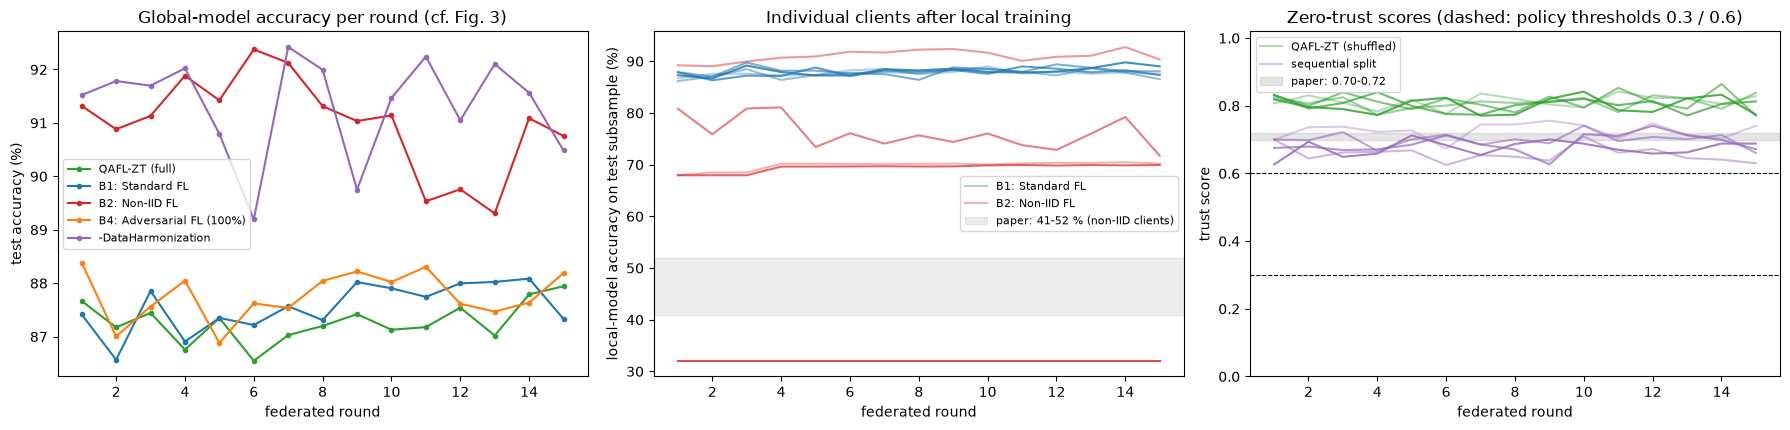

QAFL-ZT accuracy per round (seed 42): [87.67, 87.17, 87.44, 86.76, 87.35, 86.55, 87.03, 87.2, 87.42, 87.13, 87.18, 87.54, 87.02, 87.79, 87.94]
B2 accuracy per round (mean over seeds): [91.32, 90.88, 91.13, 91.88, 91.42, 92.38, 92.12, 91.31, 91.04, 91.14, 89.53, 89.76, 89.31, 91.09, 90.76]

trust components of QAFL-ZT clients, all rounds (seed 42); weights {'behavioural': 0.3, 'contextual': 0.25, 'temporal': 0.2, 'quantum': 0.25}


,beh,ctx,tmp,qnt
mean,0.992,0.745,0.995,0.501
min,0.989,0.744,0.990,0.345
max,0.995,0.746,1.000,0.723


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
for n, c in [("QAFL-ZT (full)", "tab:green"), ("B1: Standard FL", "tab:blue"), ("B2: Non-IID FL", "tab:red"), ("B4: Adversarial FL (100%)", "tab:orange"), ("-DataHarmonization", "tab:purple")]:
    H = np.array([RES[(n, s)]["hist"] for s in SEEDS]); m = H.mean(0); x = np.arange(1, len(m) + 1)
    ax[0].plot(x, m, marker="o", ms=3, label=n, color=c)
    if len(SEEDS) > 1: ax[0].fill_between(x, m - H.std(0), m + H.std(0), alpha=.15, color=c)
ax[0].set_xlabel("federated round"); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_title("Global-model accuracy per round (cf. Fig. 3)"); ax[0].legend(fontsize=8)
for n, c in [("B1: Standard FL", "tab:blue"), ("B2: Non-IID FL", "tab:red")]:
    L = np.stack([RES[(n, s)]["local_acc"] for s in SEEDS]).mean(0)          # rounds x clients (seed-averaged)
    for k in range(N_CLIENTS):
        ax[1].plot(np.arange(1, ROUNDS + 1), L[:, k], color=c, alpha=.35 + .12 * k, label=n if k == 0 else None)
ax[1].axhspan(41, 52, color="gray", alpha=.15, label="paper: 41-52 % (non-IID clients)")
ax[1].set_xlabel("federated round"); ax[1].set_ylabel("local-model accuracy on test subsample (%)"); ax[1].set_title("Individual clients after local training"); ax[1].legend(fontsize=8)
T = np.stack([RES[("QAFL-ZT (full)", s)]["taus"] for s in SEEDS]).mean(0)
T2 = np.stack([RES[("-DataHarmonization", s)]["taus"] for s in SEEDS]).mean(0)
for k in range(N_CLIENTS):
    ax[2].plot(np.arange(1, ROUNDS + 1), T[:, k], color="tab:green", alpha=.35 + .12 * k, label="QAFL-ZT (shuffled)" if k == 0 else None)
    ax[2].plot(np.arange(1, ROUNDS + 1), T2[:, k], color="tab:purple", alpha=.35 + .12 * k, label="sequential split" if k == 0 else None)
ax[2].axhspan(0.70, 0.72, color="gray", alpha=.2, label="paper: 0.70-0.72"); ax[2].axhline(0.6, ls="--", c="k", lw=.8); ax[2].axhline(0.3, ls="--", c="k", lw=.8)
ax[2].set_ylim(0, 1.02); ax[2].set_xlabel("federated round"); ax[2].set_ylabel("trust score"); ax[2].set_title("Zero-trust scores (dashed: policy thresholds 0.3 / 0.6)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

q = RES[("QAFL-ZT (full)", SEEDS[0])]
print("QAFL-ZT accuracy per round (seed %d):" % SEEDS[0], np.round(q["hist"], 2).tolist())
b2 = np.array([RES[("B2: Non-IID FL", s)]["hist"] for s in SEEDS]).mean(0)
print("B2 accuracy per round (mean over seeds):", np.round(b2, 2).tolist())
comp = pd.DataFrame(q["trust_components"]).describe().loc[["mean", "min", "max"]].round(3)
print("\ntrust components of QAFL-ZT clients, all rounds (seed %d); weights %s" % (SEEDS[0], TRUST_W)); display(comp)

### 4c. Confusion matrix and what the model misses (paper Fig. 4)

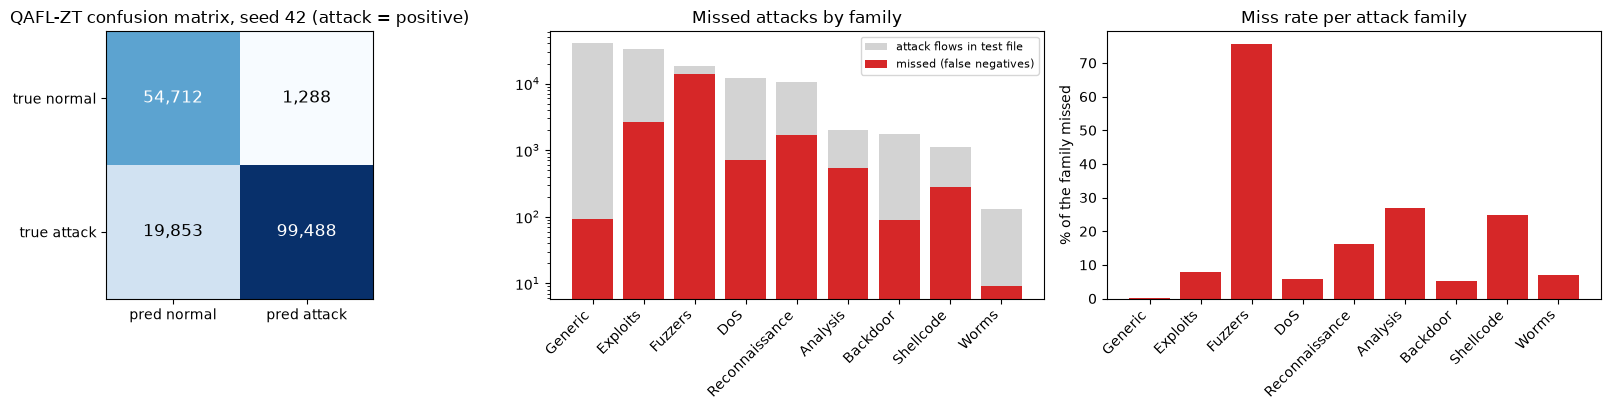

                attack flows (test)  missed  miss rate %
Generic                       40000      92          0.2
Exploits                      33393    2681          8.0
Fuzzers                       18184   13750         75.6
DoS                           12264     721          5.9
Reconnaissance                10491    1690         16.1
Analysis                       2000     539         27.0
Backdoor                       1746      89          5.1
Shellcode                      1133     282         24.9
Worms                           130       9          6.9
false-positive rate of normal traffic: 2.30 % | false-negative rate of attacks: 16.64 %


In [25]:
r = RES[("QAFL-ZT (full)", SEEDS[0])]
cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
cats_te = paper_test["attack_cat"].to_numpy()
fn_mask = (y_te == 1) & (r["pred"] == 0)
fn_by_cat = pd.Series(cats_te[fn_mask]).value_counts().reindex(CATS[1:]).fillna(0).astype(int)
tot_by_cat = pd.Series(cats_te[y_te == 1]).value_counts().reindex(CATS[1:])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
im = ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["pred normal", "pred attack"]); ax[0].set_yticklabels(["true normal", "true attack"])
for i in range(2):
    for j in range(2): ax[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax[0].set_title("QAFL-ZT confusion matrix, seed %d (attack = positive)" % SEEDS[0])
ax[1].bar(range(9), tot_by_cat.values, color="lightgray", label="attack flows in test file"); ax[1].bar(range(9), fn_by_cat.values, color="tab:red", label="missed (false negatives)")
ax[1].set_xticks(range(9)); ax[1].set_xticklabels(CATS[1:], rotation=45, ha="right"); ax[1].set_yscale("log"); ax[1].legend(fontsize=8); ax[1].set_title("Missed attacks by family")
ax[2].bar(range(9), 100 * fn_by_cat.values / tot_by_cat.values, color="tab:red"); ax[2].set_xticks(range(9)); ax[2].set_xticklabels(CATS[1:], rotation=45, ha="right")
ax[2].set_ylabel("% of the family missed"); ax[2].set_title("Miss rate per attack family")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"attack flows (test)": tot_by_cat, "missed": fn_by_cat, "miss rate %": (100 * fn_by_cat / tot_by_cat).round(1)}))
print("false-positive rate of normal traffic: %.2f %% | false-negative rate of attacks: %.2f %%" % (100 * r["fp"] / (r["fp"] + r["tn"]), 100 * r["fn"] / (r["fn"] + r["tp"])))

## 5. Robustness against FGSM and PGD (paper Table 4)

Every trained global model is attacked white-box on a fixed random subsample of the test file (`ATTACK_N` flows): FGSM at eps = 0.05, 0.10, 0.15 and PGD (10 iterations, eps = 0.10), in the standardised 36-dimensional input space, on the real feature columns only. The paper compares QAFL-ZT (40 % adversarial clients) against B1 (no adversarial training); the other configurations are attacked too, which also tests whether *selective* training is better than *universal* training.

attacks finished in 281 s


,clean,FGSM eps=0.05,FGSM eps=0.1,FGSM eps=0.15,PGD eps=0.1
configuration,,,,,
B1: Standard FL,87.33,78.52,65.97,59.26,60.02
B2: Non-IID FL,90.76,81.04,74.73,71.56,73.64
B3: Quantum centralised,88.59,79.01,68.89,60.80,59.47
B4: Adversarial FL (100%),88.19,82.05,75.71,69.48,69.09
QAFL-ZT (full),87.94,80.29,70.46,61.99,63.68
-Quantum,87.85,80.86,72.38,66.32,64.83
-Adversarial,88.01,75.42,63.41,55.11,57.89
-ZeroTrust,87.53,77.54,68.40,59.64,62.08
-DataHarmonization,90.48,85.08,79.37,74.49,78.24


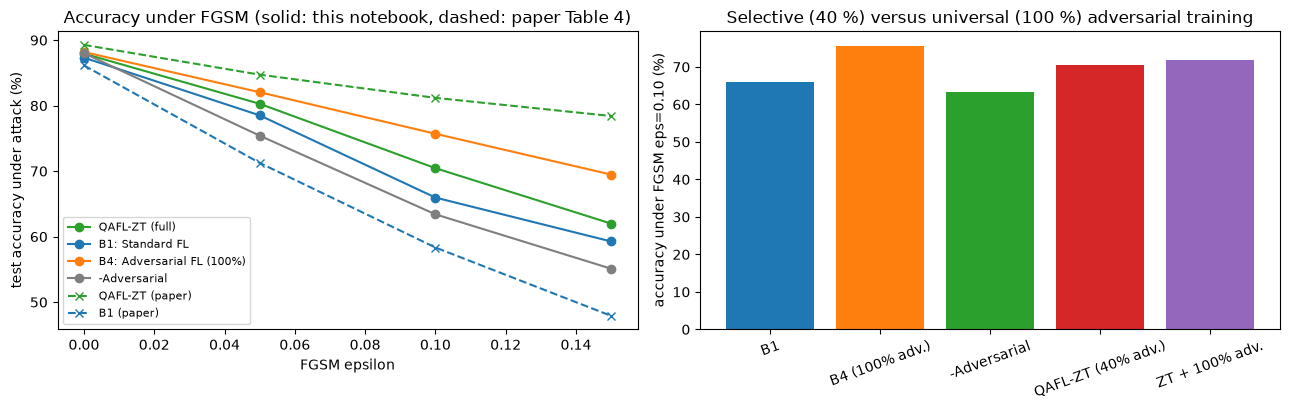

In [26]:
ATTACKS = [("FGSM", e) for e in EPS_EVAL] + [("PGD", PGD_EPS)]
ATT_IDX = torch.from_numpy(np.random.RandomState(1).choice(len(YTE), ATTACK_N, replace=False))     # CHOICE: fixed random subsample of the test file
t0 = time.time()
for (name, seed), r in RES.items():
    Xtr, Xte, mask = DESIGN[r["cfg"]["feat"]]
    m = make_model(Xte.shape[1]); m.load_state_dict(r["state"]); m.eval()
    Xs, Ys = Xte[ATT_IDX], YTE[ATT_IDX]
    adv = {}
    for kind, eps in ATTACKS:
        Xa = fgsm(m, Xs, Ys, eps, mask) if kind == "FGSM" else pgd(m, Xs, Ys, eps, PGD_ITERS, mask)
        adv[(kind, eps)] = 100 * (predict(m, Xa) == Ys).float().mean().item()
    r["adv"] = adv
print(f"attacks finished in {time.time() - t0:.0f} s")

def adv_table(names):
    rows = []
    for n in names:
        row = {"configuration": n, "clean": f"{stat(n, 'acc')[0]:.2f}"}
        for a in ATTACKS:
            v = np.array([RES[(n, s)]["adv"][a] for s in SEEDS]); row[f"{a[0]} eps={a[1]}"] = f"{v.mean():.2f}" + (f" +/- {v.std(ddof=1):.2f}" if len(v) > 1 else "")
        rows.append(row)
    return pd.DataFrame(rows).set_index("configuration")
display(adv_table(list(CONFIGS)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for n, c in [("QAFL-ZT (full)", "tab:green"), ("B1: Standard FL", "tab:blue"), ("B4: Adversarial FL (100%)", "tab:orange"), ("-Adversarial", "tab:gray")]:
    ys = [np.mean([RES[(n, s)]["acc"] for s in SEEDS])] + [np.mean([RES[(n, s)]["adv"][("FGSM", e)] for s in SEEDS]) for e in EPS_EVAL]
    ax[0].plot([0] + EPS_EVAL, ys, marker="o", label=n, color=c)
pap = {"QAFL-ZT (paper)": [89.28, 84.73, 81.19, 78.42], "B1 (paper)": [86.14, 71.26, 58.34, 47.91]}
for (n, v), c in zip(pap.items(), ["tab:green", "tab:blue"]): ax[0].plot([0] + EPS_EVAL, v, ls="--", marker="x", color=c, label=n)
ax[0].set_xlabel("FGSM epsilon"); ax[0].set_ylabel("test accuracy under attack (%)"); ax[0].set_title("Accuracy under FGSM (solid: this notebook, dashed: paper Table 4)"); ax[0].legend(fontsize=8)
names = ["B1: Standard FL", "B4: Adversarial FL (100%)", "-Adversarial", "QAFL-ZT (full)", "Extra: QAFL-ZT with universal adversarial training (100% clients)"]
for j, n in enumerate(names):
    ax[1].bar(j, np.mean([RES[(n, s)]["adv"][("FGSM", 0.10)] for s in SEEDS]), color=plt.cm.tab10(j))
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(["B1", "B4 (100% adv.)", "-Adversarial", "QAFL-ZT (40% adv.)", "ZT + 100% adv."], rotation=20); ax[1].set_ylabel("accuracy under FGSM eps=0.10 (%)")
ax[1].set_title("Selective (40 %) versus universal (100 %) adversarial training")
plt.tight_layout(); plt.show()

## 6. Side-by-side comparison with the paper

Each row is one checkable claim. A value is **reproduced** when this notebook's mean is within the tolerance of the paper's number (2 points for accuracy / precision / recall / F1 x 100 and for accuracy under attack, 1 point for differences between configurations), **exceeded** when it is higher by more than the tolerance, **not reached** when it is lower. **cannot be checked** is used when the quantity depends on hardware or is not derivable. Training times are printed for information only (the paper used a GPU with mixed precision; this notebook a shared CPU).

In [27]:
def verdict(paper, ours, tol):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
def add(cid, claim, paper, ours, tol, fmt="{:.2f}"):
    rows.append(dict(id=cid, claim=claim, paper=fmt.format(paper) if paper is not None else "-", notebook=fmt.format(ours) if ours is not None and not (isinstance(ours, float) and np.isnan(ours)) else "n/a",
                     verdict=verdict(paper, ours, tol) if paper is not None else "cannot be checked"))

mean = lambda n, k: stat(n, k)[0]
# ---- Table 2
T2 = {"B1: Standard FL": (86.14, 92.73, 84.22, 88.28, 98.2), "B2: Non-IID FL": (83.99, 94.12, 81.58, 87.40, 153.3), "B3: Quantum centralised": (87.45, 93.81, 86.12, 89.82, 76.4),
      "B4: Adversarial FL (100%)": (85.72, 91.44, 85.91, 88.60, 187.6), "QAFL-ZT (full)": (89.28, 98.51, 85.55, 91.57, 143.4)}
for n, (a, p, r_, f, t) in T2.items():
    tag = n.split(":")[0] if ":" in n else "QAFL-ZT"
    for key, lab, pv in [("acc", "accuracy", a), ("prec", "precision", p), ("rec", "recall", r_), ("f1", "F1", f)]:
        add("C1", f"Table 2, {tag}: {lab} (%)", pv, mean(n, key), 2.0)
    rows.append(dict(id="C1", claim=f"Table 2, {tag}: training time (s); GPU vs shared CPU, runs trained in lockstep", paper=f"{t:.1f}", notebook="n/a", verdict="cannot be checked"))
# ---- Table 3
T3 = [("QAFL-ZT (full)", 89.28), ("-Quantum", 87.91), ("-Adversarial", 88.73), ("-ZeroTrust", 88.89), ("-DataHarmonization", 84.82), ("-Quantum -Adversarial", 86.54), ("B2: Non-IID FL", 83.12)]
for n, pv in T3:
    add("C2", f"Table 3, {n if n != 'B2: Non-IID FL' else 'classical baseline (= B2)'}: accuracy (%)", pv, mean(n, "acc"), 2.0)
full = mean("QAFL-ZT (full)", "acc")
for n, pd_ in [("-Quantum", 1.37), ("-Adversarial", 0.55), ("-ZeroTrust", 0.39), ("-DataHarmonization", 4.46)]:
    add("C2", f"Table 3, drop when removing {n[1:]} (points)", pd_, full - mean(n, "acc"), 1.0)
# ---- ranking / contribution claims
drops = {n: full - mean(n, "acc") for n in ["-Quantum", "-Adversarial", "-ZeroTrust", "-DataHarmonization"]}
rows.append(dict(id="C3", claim="Data harmonisation is the largest single contribution", paper="4.46 (largest)", notebook="; ".join(f"{k[1:]} {v:.2f}" for k, v in drops.items()),
                 verdict="reproduced" if max(drops, key=drops.get) == "-DataHarmonization" else "not reached"))
rows.append(dict(id="C3", claim="Data harmonisation > quantum + adversarial + zero-trust together", paper="4.46 > 2.31", notebook=f"{drops['-DataHarmonization']:.2f} vs {drops['-Quantum'] + drops['-Adversarial'] + drops['-ZeroTrust']:.2f}",
                 verdict="reproduced" if drops["-DataHarmonization"] > drops["-Quantum"] + drops["-Adversarial"] + drops["-ZeroTrust"] else "not reached"))
# ---- text claims on baselines
add("C6", "B1 - B2: accuracy lost to non-IID split (points)", 2.15, mean("B1: Standard FL", "acc") - mean("B2: Non-IID FL", "acc"), 1.0)
add("C6", "B3 - B1: accuracy gained by quantum features, centralised (points)", 1.31, mean("B3: Quantum centralised", "acc") - mean("B1: Standard FL", "acc"), 1.0)
add("C6", "B1 - B4: cost of universal adversarial training (points)", 0.42, mean("B1: Standard FL", "acc") - mean("B4: Adversarial FL (100%)", "acc"), 1.0)
sel, uni = mean("QAFL-ZT (full)", "acc"), mean("Extra: QAFL-ZT with universal adversarial training (100% clients)", "acc")
rows.append(dict(id="C6", claim="Selective (40 %) adversarial training >= universal (100 %), all else equal (QAFL-ZT vs QAFL-ZT with 100 %)", paper="selective better", notebook=f"{sel:.2f} vs {uni:.2f}", verdict="reproduced" if sel >= uni else "not reached"))
allm = {n: mean(n, "acc") for n in MAIN}
rows.append(dict(id="C1", claim="QAFL-ZT has the highest accuracy of the five configurations of Table 2", paper="yes", notebook=f"best = {max(allm, key=allm.get)} ({max(allm.values()):.2f})", verdict="reproduced" if max(allm, key=allm.get) == "QAFL-ZT (full)" else "not reached"))
if len(SEEDS) > 1:
    dq = np.array([RES[("QAFL-ZT (full)", s)]["acc"] - RES[("-Quantum", s)]["acc"] for s in SEEDS])
    add("C2", "quantum gain (QAFL-ZT minus -Quantum): mean over seeds (points)", 1.37, dq.mean(), 1.0)
    rows.append(dict(id="C2", claim="quantum gain 'consistent across seeds' (std 0.21)", paper="std 0.21", notebook=f"std {dq.std(ddof=1):.2f}; sign positive in {int((dq > 0).sum())}/{len(dq)} seeds", verdict="reproduced" if (dq > 0).all() else "not reached"))
else:
    rows.append(dict(id="C2", claim="quantum gain consistent across seeds", paper="std 0.21 over 5 seeds", notebook="1 seed", verdict="cannot be checked"))
# ---- C4: split composition
att, nor = client_mix["sequential"]; att2, nor2 = client_mix["shuffle"]
add("C4", "sequential split: attack share of client 0 (%)", 98.5, 100 * att[0] / (att[0] + nor[0]), 2.0)
add("C4", "sequential split: attack share of client 4 (%)", 0.0, 100 * att[4] / (att[4] + nor[4]), 2.0)
sh = 100 * att2 / (att2 + nor2)
rows.append(dict(id="C4", claim="shuffled split: every client 54-55 % attack", paper="54-55", notebook=f"{sh.min():.1f}-{sh.max():.1f}", verdict="reproduced" if sh.min() > 53.5 and sh.max() < 55.5 else "not reached"))
# ---- C5: Table 4
T4 = {("FGSM", 0.05): (84.73, 71.26), ("FGSM", 0.10): (81.19, 58.34), ("FGSM", 0.15): (78.42, 47.91), ("PGD", 0.10): (79.87, 54.12)}
for a, (pq, pb) in T4.items():
    add("C5", f"Table 4, QAFL-ZT under {a[0]} eps={a[1]}: accuracy (%)", pq, np.mean([RES[("QAFL-ZT (full)", s)]["adv"][a] for s in SEEDS]), 2.0)
    add("C5", f"Table 4, B1 under {a[0]} eps={a[1]}: accuracy (%)", pb, np.mean([RES[("B1: Standard FL", s)]["adv"][a] for s in SEEDS]), 2.0)
gain = np.mean([RES[("QAFL-ZT (full)", s)]["adv"][("FGSM", 0.10)] - RES[("B1: Standard FL", s)]["adv"][("FGSM", 0.10)] for s in SEEDS])
add("C5", "robustness gain of QAFL-ZT over B1 under FGSM eps=0.10 (points)", 22.85, gain, 5.0)
# ---- C7: trust
tz = np.concatenate([RES[("QAFL-ZT (full)", s)]["taus"].ravel() for s in SEEDS])
rows.append(dict(id="C7", claim="zero-trust scores of benign clients (shuffled split) lie in 0.70-0.72", paper="0.70-0.72", notebook=f"{tz.min():.3f}-{tz.max():.3f} (mean {tz.mean():.3f})", verdict="reproduced" if abs(tz.mean() - 0.71) <= 0.05 else "not reached"))
# ---- C8: confusion matrix
cmx = RES[("QAFL-ZT (full)", SEEDS[0])]
for nm, pv, ov in [("true negatives", 64132, cmx["tn"]), ("true positives", 92470, cmx["tp"]), ("false positives", 1347, cmx["fp"]), ("false negatives", 17392, cmx["fn"])]:
    rows.append(dict(id="C8", claim=f"Fig. 4: {nm}", paper=f"{pv:,}", notebook=f"{ov:,}", verdict=verdict(pv / 175341 * 100, ov / 175341 * 100, 2.0)))
rows.append(dict(id="C8", claim="Fig. 4: class totals of the test file (normal / attack) as implied by the matrix", paper="65,479 / 109,862", notebook=f"{int((y_te == 0).sum()):,} / {int((y_te == 1).sum()):,} (official file)", verdict="not reached"))
# ---- C9: dynamics
hq = np.array([RES[("QAFL-ZT (full)", s)]["hist"] for s in SEEDS]).mean(0); hb2 = np.array([RES[("B2: Non-IID FL", s)]["hist"] for s in SEEDS])
add("C9", "QAFL-ZT accuracy after round 1 (%)", 87.64, hq[0], 2.0)
add("C9", "QAFL-ZT accuracy after the last round (%)", 89.28, hq[-1], 2.0)
rows.append(dict(id="C9", claim="QAFL-ZT improves 'smoothly and monotonically' over rounds", paper="monotone", notebook=f"{int((np.diff(hq) < 0).sum())} decreasing steps out of {len(hq) - 1}", verdict="reproduced" if (np.diff(hq) >= -0.1).all() else "not reached"))
rows.append(dict(id="C9", claim="B2 never exceeds 84.5 % in any round and oscillates (+/- 2.3 %)", paper="max 84.5, std 2.3", notebook=f"max {hb2.mean(0).max():.2f}, std over rounds {hb2.mean(0)[len(hb2.mean(0)) // 3:].std():.2f}", verdict="reproduced" if hb2.mean(0).max() <= 85.5 else "not reached"))
la = np.stack([RES[("B2: Non-IID FL", s)]["local_acc"] for s in SEEDS])
rows.append(dict(id="C9", claim="non-IID clients' local accuracy falls between 41 % and 52 %", paper="41-52", notebook=f"{la.min():.1f}-{la.max():.1f}", verdict="reproduced" if la.min() >= 36 and la.max() <= 57 else "not reached"))
CMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.max_rows", 200)
display(CMP[["id", "claim", "paper", "notebook", "verdict"]].style.hide(axis="index"))
print("\nverdict counts:", CMP["verdict"].value_counts().to_dict())

id,claim,paper,notebook,verdict
C1,"Table 2, B1: accuracy (%)",86.14,87.33,reproduced
C1,"Table 2, B1: precision (%)",92.73,98.73,exceeded
C1,"Table 2, B1: recall (%)",84.22,82.45,reproduced
C1,"Table 2, B1: F1 (%)",88.28,89.86,reproduced
C1,"Table 2, B1: training time (s); GPU vs shared CPU, runs trained in lockstep",98.2,n/a,cannot be checked
C1,"Table 2, B2: accuracy (%)",83.99,90.76,exceeded
C1,"Table 2, B2: precision (%)",94.12,94.61,reproduced
C1,"Table 2, B2: recall (%)",81.58,91.64,exceeded
C1,"Table 2, B2: F1 (%)",87.40,93.10,exceeded
C1,"Table 2, B2: training time (s); GPU vs shared CPU, runs trained in lockstep",153.3,n/a,cannot be checked



verdict counts: {'reproduced': 26, 'not reached': 20, 'exceeded': 15, 'cannot be checked': 6}


## 7. Reading the paper critically

*(Numbers below are from the saved run: seed 42, 15 rounds, 1 local epoch, FAST_MODE = False. Section 6 has the claim-by-claim table.)*

**What reproduces.**
- The split statistics are exact: the sequential cut of the shipped 82,332-flow file gives client 0 = 98.5 % attack and client 4 = 100 % normal, and the shuffled cut gives 54.7-55.4 % attack per client (claim C4). This also confirms that the paper trained on the 82,332-flow file and tested on the 175,341-flow one.
- The level of the headline numbers is right: shuffled federated models with the 36-dimensional input reach 87.3-88.6 % accuracy and about 98.5 % precision (paper: QAFL-ZT 89.28 % / 98.51 %). Accuracy is within the 2-point tolerance for 3 of the 5 configurations of Table 2, and QAFL-ZT's precision and F1 are reproduced.
- Centralised quantum features beat the federated baseline B1 by 1.26 points (paper: 1.31).

**What does not reproduce.**
1. **The "98.51 % precision" is not a property of QAFL-ZT.** Every shuffled model here (B1, B3, B4 and all ablations) has a precision of 98.5-98.8 %, whereas the paper lists 91-94 % for the baselines. The test file simply contains normal traffic that is easy to recognise; precision is saturated and recall (82-85 %) is where the models differ.
2. **The ablation ordering is not supported.** Removing quantum features changes accuracy by +0.09 points, removing adversarial training by -0.07, removing zero trust by +0.42; the paper reports 1.37, 0.55 and 0.39. With one seed and round-to-round swings of about 0.5 points in Fig. 3, none of these three differences is distinguishable from noise. The 1.37-point quantum gain is therefore *not reached*; the claim that it is "consistent across five seeds" could not be tested with one seed.
3. **Data harmonisation is not the winner here; the sign flips.** The *sequential* (pathological) split, B2, gets **90.8 %**, the best accuracy of all runs, against 87.3 % for the shuffled B1, while the paper reports 83.99 % vs 86.14 % (and a 4.46-point harm). The threshold-free ROC-AUC tells the opposite story (B2 96.8 %, B1 98.2 %): the non-IID models are worse rankers but happen to sit at a better operating point. The test file is 68 % attack, the training file 55 %; FedAvg of clients that are 98-100 % attack or 100 % normal shifts the decision threshold towards "attack" and raises recall from 82 % to 92 %. Accuracy under such a prior shift is a fragile yardstick; this is the most important caveat on the paper's central finding.
4. **Robustness is far smaller than in Table 4.** Under FGSM at eps = 0.10 QAFL-ZT keeps 70.5 % (paper 81.2 %) and B1 66.0 % (paper 58.3 %); the 22.85-point gap becomes 4.5 points. Universal adversarial training (B4, 75.7 %) is *more* robust than the selective 40 % scheme, and the quantum features do not help (the "-Quantum" run is more robust, 72.4 %). The result depends on the attack space (here the standardised 36-dimensional network input, including the 16 quantum probabilities); the paper does not say which space ART attacked.
5. **Zero trust never acts.** The trust scores are 0.77-0.86 (paper 0.70-0.72); the behavioural and temporal components are about 1, the "quantum-inspired" component is a hash-derived constant near 0.5. Even on the pathological sequential split all clients stay above the 0.6 threshold, so no client is ever down-weighted or denied. The trust formulas use only feature means and a clock, never labels or gradients, so a label-flipping or poisoned client would not be detected. The paper itself concedes that zero trust "contributes minimally" and was not tested against any malicious client.
6. **Unreproducible text statements.** The training curve of QAFL-ZT is not monotone (5 decreasing steps in 14); B2 reaches 92.4 % (paper: never above 84.5 %); the individual non-IID clients' accuracies (32-93 % on a 175k-flow test subsample, 32 % being the share of normal flows for the all-normal client) do not fall in 41-52 %.

**Internal inconsistencies in the paper.**
- *Fig. 4 does not match the dataset.* Its matrix implies 65,479 normal and 109,862 attack flows; the official 175,341-flow file has 56,000 and 119,341. Computed from its own matrix, accuracy is 89.31 % (reported 89.28 %), precision 98.56 % (98.51 %) and recall 84.17 % (85.55 %). The text says the missed attacks come from "Worms: 44 samples, Backdoor: 583 samples": these are the sizes of those classes in the 82,332-flow *training* file (see the class counts above), not numbers of missed flows. Here 69 % of all missed attacks are Fuzzers (75.6 % of that family is missed), followed by Exploits, Analysis and Reconnaissance; Worms and Backdoor contribute 98 of 19,853 misses.
- The classical baseline "all components removed" is B2 by definition, yet Table 3 gives 83.12 % and Table 2 83.99 %. "Selective beats universal by 0.87 points" cannot be derived from Tables 2-3 (B4 is 0.42 below B1, 3.56 below QAFL-ZT). The text says SGD, Table 1 says Adam.
- B3 differs from B1 in two things (quantum features *and* centralised training), so "B3 - B1" is not a clean measure of the quantum gain.

**Is the quantum part doing anything?** The circuit has fixed, untrained angles, so it is a random 16-dimensional feature map of 4 PCA components. It is not compared with a classical random map of the same size. In the paper's literal construction only 1,000 of 82,332 training flows (1.2 %) carry quantum features and *no* test flow does, so the deployed model sees zero-padded PCA only; our literal variant (88.13 %) is indistinguishable from the classical models. The honest reading, which the paper also hints at, is that the quantum contribution is below what a single seed can resolve.

**Scope of this reproduction.** One seed (42), 1 local epoch per round instead of 3, an attack evaluated on 60,000 test flows, public mirror of the same dataset. Differences below about 0.5 accuracy points should not be interpreted. Status: **partially reproduced**.

## 8. Exercises

1. **Seeds.** Set `SEEDS = [42, 43, 44]` (about three times the run time) and re-read Section 6: which of the ablation differences (quantum, adversarial, zero trust) have a mean larger than twice its standard deviation?
2. **Paper-faithful local epochs.** Set `LOCAL_EPOCHS = 3`. Do the round-to-round oscillations of Fig. 3 shrink, and does B1 move towards or away from the paper's 86.14 %?
3. **Operating point versus ranking.** For B1 and B2, pick a decision threshold on a held-out part of the *training* file (for instance the one that maximises F1) and report accuracy and recall again. How much of the "B2 beats B1" effect remains? Then re-weight the loss to a 68 % attack prior.
4. **A classical control for the circuit.** Replace `fast_probs` by 16 random Fourier features of the same four PCA angles (same input size, no circuit). Does the 0.1-point quantum gain survive? Then train the 16 angles `theta` (SPSA or parameter shift on a small centralised classifier) and test whether trained angles beat the random ones.
5. **A malicious client.** Flip the labels of one client in `FedRun.prepare` and compare plain FedAvg with the paper's trust-weighted aggregation. Design a fifth trust component that uses the client's update (for example its cosine similarity to the mean update) and show whether it excludes the attacker.

In [28]:
print("total wall-clock time of this run: %.1f min (FAST_MODE = %s, seeds %s)" % ((time.time() - NOTEBOOK_T0) / 60, FAST_MODE, SEEDS))

total wall-clock time of this run: 34.4 min (FAST_MODE = False, seeds [42])
